# Four-channel AD3552R DAC: circuit design and verification tutorial

**Standalone design notebook | Two AD3552R devices | Four 16-bit outputs | ADA4807-1 transimpedance stages | Red Pitaya STEMlab 125-14 4-Input / LQG actuation**

This notebook assembles the **complete reference-level circuit design** developed alongside the levitated-optomechanics LQG notebook. It contains the circuit drawings, signal and pin mappings, transimpedance amplifier (TIA) connections, supply and reference networks, example register settings, update timing, bill of materials, numerical checks, and a bring-up checklist.

**Output stage: the manufacturer's ADA4807-1 reference circuit.** Every DAC output uses the amplifier and component values with which the AD3552R data sheet measures its dynamic specifications: an **ADA4807-1** TIA closed through the on-chip `RFB2` resistor, an **8.2 pF NP0 feedback capacitor**, and `VCM` decoupled with **0.1 uF**. Section 7.1 models this stage numerically: bandwidth, phase margin, slew rate and settling.

**Controller: Red Pitaya STEMlab 125-14 4-Input.** The LQG controller runs in the Zynq-7020 of a 4-input Red Pitaya, which has four 125 MS/s inputs and no fast outputs. Section 10 specifies the interface between them: level translators from the 3.3 V `E1` header to the DACs' 1.8 V logic, a pin-by-pin map with Zynq ball numbers, power and grounding, the HDL blocks, the exact quad-SPI frame, timing margins, the register initialisation sequence, and an end-to-end latency budget that sets the update decimation $N$.

**Design status: illustrative engineering reference, not a fabrication-ready schematic.** The graphics show electrical intent and matching net names, not an editable, electrical-rule-checked CAD netlist. The feedback capacitor is the manufacturer's characterisation value; it must still be confirmed on the actual layout and load before hardware is built.

This is **a separate notebook**: it needs only NumPy and Matplotlib for its calculations (Section 10.9 additionally uses the `pylqg` package when it is run from `pylqg_project/notebooks`). The LQG notebook (`pylqg_tutorial.ipynb`, Section 12) uses the same ADA4807-1 stage as part of its plant model.

## 1. Design requirements, provenance, and limitations

### What came from the earlier numerical notebook

The original design study considers a plant sensed every $T_s=64$ ns and a **lifted, multirate LQR** actuator that only changes its commanded voltage every $N=24$ fast samples. The proposed hardware is **two AD3552R devices**, each with two DAC channels, and a common update strobe. In that source notebook, the ADC latency (96 ns), an idealised quad-SPI write, a 20 ns update allowance, and a 100 ns DAC settling allowance add to about 398 ns. Those numbers are **assumptions in a model**, not verified bench results. Section 10.9 replaces them with a budget for the Red Pitaya, built from the parts actually in the path.

### Independently checked against manufacturer documentation

- The **AD3552R is a dual-channel, 16-bit current-output DAC**, and **requires external TIAs** to generate voltages. It provides internal selectable gain feedback resistors. [AD3552R datasheet, Rev. B](https://www.analog.com/media/en/technical-documentation/data-sheets/ad3552r.pdf), pp. 1, 26-27 and 68.
- The **RFB2** resistor and **output-range selection code `0b011` per channel** are paired for the nominal **-5 V to +5 V** span (datasheet Table 8, p. 26; register map, p. 57).
- Both chips can use **quad SPI** and a **shared, active-low LDAC** to command output updates (datasheet pp. 34-37). That does **not** establish a guaranteed 5 ns cross-chip output skew.
- **100 ns large-signal settling** is quoted **to 0.1%**, not to 16-bit resolution (datasheet p. 1), and it is measured in the **0 V to 5 V range** (`RFB1`, Table 3). The **±5 V range uses `RFB2`, twice the resistance**, so the same amplifier and capacitor settle about twice as slowly (Section 7.1: about 180 ns to 0.1%).
- **The data sheet's AC characteristics are "measured with the ADA4807-1 external amplifier"** (Table 3). Its plots give the component values: **C_FB = 8.2 pF** for the 2.5 V, 5 V and ±5 V ranges and 6.8 pF for the 10 V range, with **R_LOAD = 1 kOhm** (Figures 53-59). Figure 59 gives the resulting slew rate, about **180 V/us** in the ±5 V range at 25 C. This is the reference circuit used here; Figure 94 gives its topology and decoupling.
- The **ADA4807-1** (ADA4807 data sheet) has 180 MHz small-signal bandwidth (G = +1), 225 V/us slew rate, 1 pF + 1 pF input capacitance, a **2.7 V to 11 V total supply**, rail-to-rail output (within about 40-100 mV of the rails into 1 kOhm), and about 50 mA / 60 mA linear output current (source / sink).

- The **Red Pitaya STEMlab 125-14 4-Input** (Red Pitaya documentation and the board's constraint file in the RedPitaya-FPGA repository) has a Zynq-7020, two dual LTC2145-14 ADCs (four 14-bit, 125 MS/s inputs), **no fast analog outputs**, and a 26-pin `E1` header with 22 general-purpose pins at **3.3 V LVCMOS**. The DACs' logic runs from `VLOGIC` = 1.1 V to 1.89 V, so **level translation is required** (Section 10.2).

**Not specified by the available sources:** load impedance and capacitance, the DAC's `IOUT` pin capacitance (needed for an exact stability calculation), exact regulator part numbers, and measured DAC-to-actuator settling. These remain design decisions or measurements, not facts. The 8.2 pF feedback capacitor is the manufacturer's *characterisation* value; Section 7.1 shows that it is robust to the unknown capacitance, but it should still be confirmed on the real board.

## 2. Top-level architecture

| Block | Reference choice | Function |
|---|---|---|
| Controller | **Red Pitaya STEMlab 125-14 4-Input** (Zynq-7020, 4 x 14-bit 125 MS/s inputs) | Samples the detectors, computes four actuator codes, drives quad SPI + LDAC on `E1` (3.3 V) |
| U8-U11 | **4 x 74AVC4T774** level translators (Section 10.2) | 3.3 V `E1` <-> 1.8 V DAC logic, FPGA-controlled direction for readback |
| U1, U2 | **2 x AD3552R** | Two 16-bit current DACs per chip |
| U3-U6 | **4 x ADA4807-1** (manufacturer's characterisation amplifier) | External TIA for each current output, C_FB = 8.2 pF |
| Reference | **2.5 V**, e.g. ADR4525, external option | DAC reference; internal 2.5 V is also possible |
| Digital rails | **1.8 V** (`DVDD`, `VLOGIC`, translator `VCCB`); translator `VCCA` from `E1` +3.3 V | Core logic and the DAC side of the interface |
| Power input | **one +12 V input**; all rails made on the board (Section 8.1) | TPS7A4901, LTC3260, AP63201 + TLV75518P |
| Analog rail | **+5 V** (`AVDD`) | DAC analog supply |
| Op-amp rails | **+5 V / -5 V** (10 V total; ADA4807-1 maximum 11 V) | Output swing about +/-4.9 V: the +/-5 V range is usable except its outer ~3% (clamp at +/-4.85 V) |
| DAC update | Common active-low **LDAC** | Synchronises conversion of staged codes |
| Output load | **Electrode pairs, push-pull** (Section 5.1): `OUTx+` = +V, `OUTx-` = -V | 8 SMA jacks, 50 Ohm coax, 49.9 Ohm source termination |

**Output assignment:** U1/CH0 = OUT0, U1/CH1 = OUT1, U2/CH0 = OUT2, U2/CH1 = OUT3. A three-axis experiment may leave OUT3 spare.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.set_xlim(-0.35, 12); ax.set_ylim(0, 3.5); ax.axis('off')
def block(x,y,w,h,lab,color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.05',
                                fc=color,ec='#374a60',lw=1.2))
    ax.text(x+w/2,y+h/2,lab,ha='center',va='center',fontsize=10)
def conn(a,b,lab=''):
    ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='->',lw=1.8,color='#3b526e'))
    if lab: ax.text((a[0]+b[0])/2,(a[1]+b[1])/2+.13,lab,ha='center',fontsize=8)
block(.15,.65,1.6,2.1,'Red Pitaya\n125-14 4-Input\nZynq-7020 / LQG\nE1: 3.3 V','#e9f2fd')
block(2.35,.65,1.0,2.1,'U8-U11\n3.3 V to\n1.8 V','#fff6e6')
ax.annotate('',xy=(.1,1.7),xytext=(-.3,1.7),arrowprops=dict(arrowstyle='->',lw=1.8,color='#3b526e')); ax.text(-.3,1.9,'IN1-4',fontsize=8)
block(3.95,1.95,2.05,.95,'U1 AD3552R\nCH0, CH1','#e8f5ed')
block(3.95,.45,2.05,.95,'U2 AD3552R\nCH0, CH1','#e8f5ed')
block(7.0,1.95,2.05,.95,'U3, U4 TIAs\nU16, U17 inverters','#fff1dc')
block(7.0,.45,2.05,.95,'U5, U6 TIAs\nU18, U19 inverters','#fff1dc')
block(9.9,.65,1.75,2.1,'Electrode pairs\nOUT0+/- ... OUT3+/-\n8 x SMA','#f2e8fc')
conn((1.8,1.7),(2.3,1.7))
for a,b,l in [((3.35,2.15),(3.95,2.4),'SPI A'),((3.35,1.15),(3.95,.9),'SPI B'),
              ((6,2.4),(7,2.4),'IOUT0/1'),((6,.9),(7,.9),'IOUT0/1'),
              ((9.05,2.4),(9.9,2.1),'V0/V1'),((9.05,.9),(9.9,1.15),'V2/V3')]:conn(a,b,l)
ax.plot([3.85,3.85],[.9,2.4],ls='--',color='#9466aa'); ax.text(3.85,3.1,'Shared SCLK, LDAC (1.8 V)',fontsize=8,ha='center',color='#724c8c')
ax.set_title('Four-channel architecture (functional blocks, not a PCB schematic)',fontsize=14,pad=12)
plt.show()

## 3. Digital circuit: FPGA to two AD3552Rs

The diagram below is the two-chip interface drawing from the prior design. **Wires with matching net names are electrically connected**; abbreviated bundle lines represent groups of nets. It is a block-level schematic of the DAC side. **With the Red Pitaya, the left-hand "FPGA / LQG controller" box is the STEMlab 125-14 4-Input plus the translator board of Section 10**: the nets drawn here are the 1.8 V side of the translators, and **Sheet 3** (Section 10.3) maps them to `E1` pins and Zynq balls. Sheet 1's footer quotes two separate channel writes at 66 MHz; Section 10 uses one streamed 10-SCLK frame at 62.5 or 31.25 MHz, the rates the Red Pitaya's 125 MHz clock divides to.

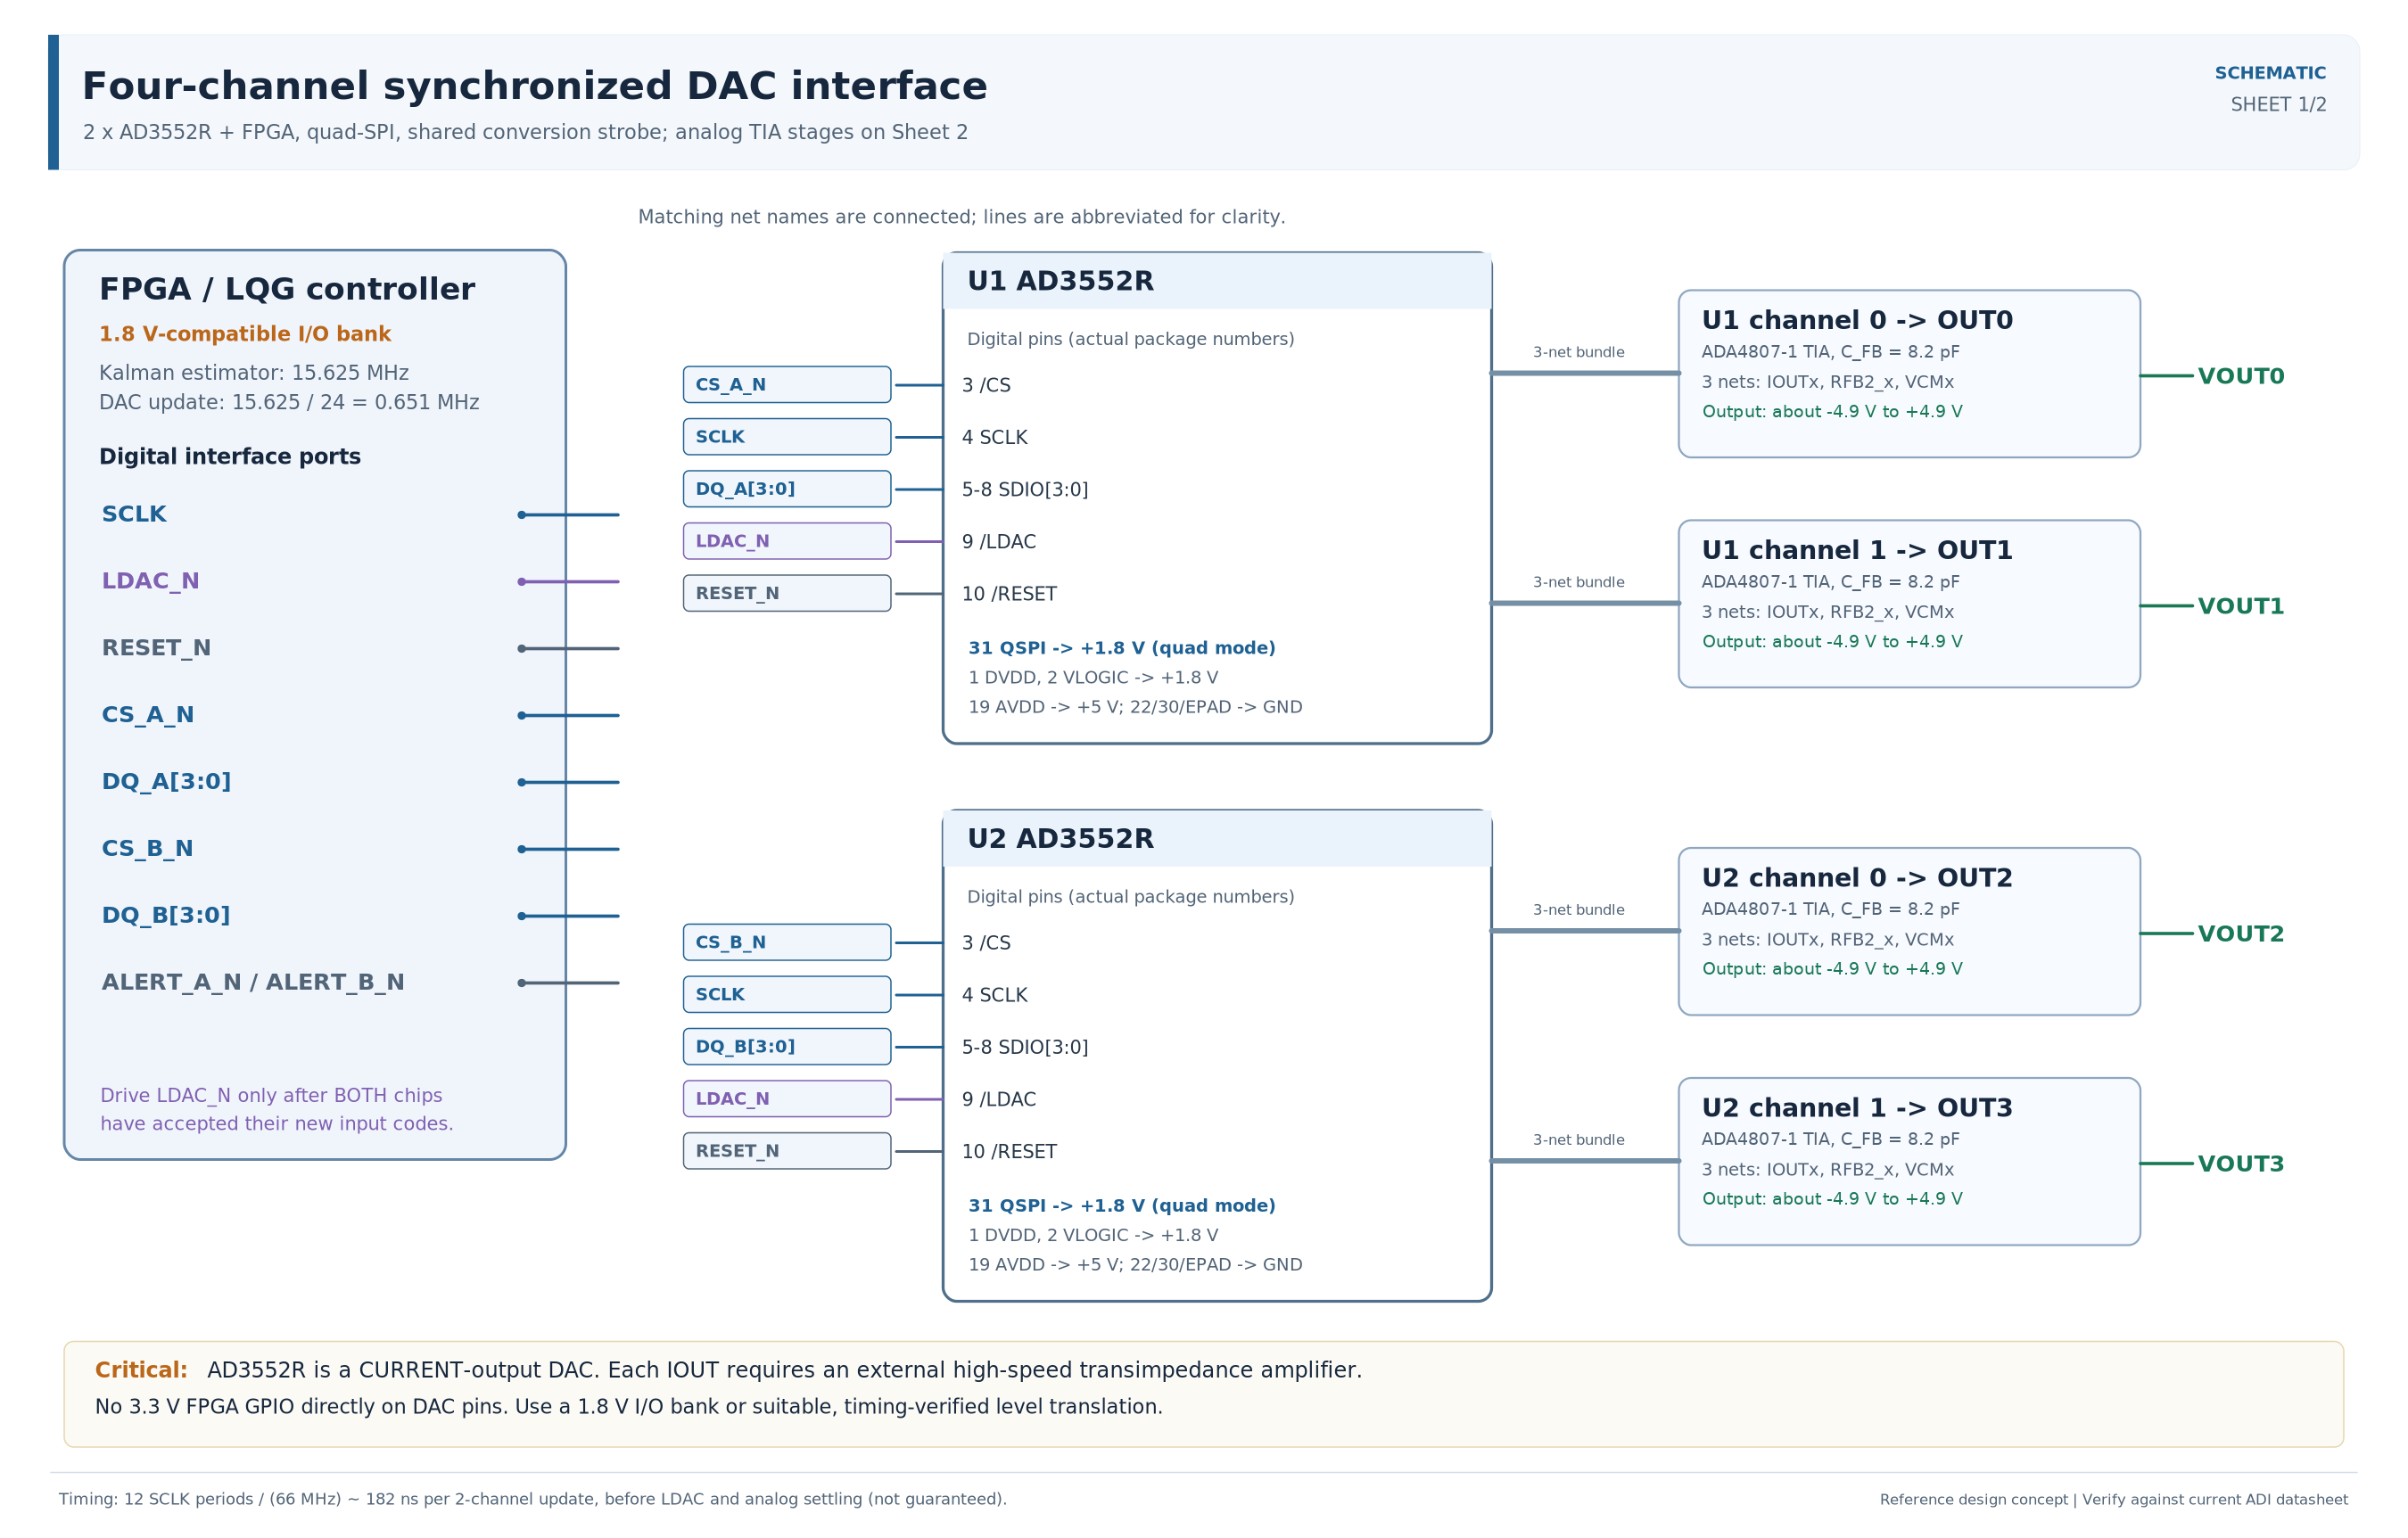

*Sheet 1: dual-device quad-SPI interface and four synchronized outputs (ADA4807-1 TIA stages detailed on Sheet 2)*

### Signal-by-signal wiring

| Net | FPGA side (Red Pitaya `E1` pin: Section 10.3) | DAC U1 | DAC U2 | Why it matters |
|---|---|---|---|---|
| `SCLK` | Clock output, 1.8 V | Pin **4** | Pin **4** | Shared serial clock |
| `CS_A_N` | Dedicated output | Pin **3** | - | Select U1, active low |
| `CS_B_N` | Dedicated output | - | Pin **3** | Select U2, active low |
| `DQ_A[0:3]` | Four bidirectional-capable or driven FPGA signals | Pins **5,6,7,8** | - | Quad-SPI lanes for U1 |
| `DQ_B[0:3]` | Four separate FPGA signals | - | Pins **5,6,7,8** | Quad-SPI lanes for U2 |
| `LDAC_N` | Common timing output | Pin **9** | Pin **9** | Assert **after** both chips contain valid new input codes |
| `RESET_N` | Shared or individually gated output | Pin **10** | Pin **10** | Reset; hold inactive high when operating |
| `ALERT_A_N` | Status input | Pin **11** | - | Error indication from U1 |
| `ALERT_B_N` | Status input | - | Pin **11** | Error indication from U2 |
| `QSPI` | Static strap, not an SPI data lane | Pin **31**, 1 kOhm to `VLOGIC` | Pin **31**, 1 kOhm to `VLOGIC` | Selects quad mode (Figure 94) |
| `DVDD` | Local regulator | Pin **1**, +1.8 V | Pin **1**, +1.8 V | Core supply |
| `VLOGIC` | Logic supply | Pin **2**, +1.8 V | Pin **2**, +1.8 V | Digital I/O levels |
| `AVDD` | Analog supply | Pin **19**, +5 V | Pin **19**, +5 V | Analog supply |
| `DGND`, `AGND`, exposed pad | Ground plane | Pins **30**, **22**, EPAD | Same | Common return, with local noise-aware routing |

**Electrical interface rule:** the DAC logic pins are intended for roughly 1.2 V / 1.8 V logic. A 3.3 V FPGA bank **must not connect directly**. The Red Pitaya's `E1` pins are 3.3 V LVCMOS, so this design uses explicit-direction translators (74AVC4T774) whose timing is checked in Section 10.7. The CS signals are separate, but both chips may be written concurrently using two independent quad-data groups and a shared SCLK.

**Clock-polarity configuration:** the AD3552R supports SPI modes 0 and 3 in SDR; check the CPOL/CPHA constraints in datasheet p. 34. Sample/data phase turnaround and drive strength are not optional details for readback.

## 4. Complete AD3552R package pin map (repeat for U1 and U2)

The following is the **32-pin LFCSP** device pinout from the AD3552R Rev. B datasheet, Figure 13 and Table 7 (pp. 12-13). It is not a board connector pinout.

| Pin | Name | Reference connection or role |
|---:|---|---|
| 1 | DVDD | +1.8 V, local decoupling |
| 2 | VLOGIC | +1.8 V, local decoupling |
| 3 | /CS | Independent per-device FPGA select |
| 4 | SCLK | Shared FPGA clock |
| 5 | SDI/SDIO0 | Quad data lane 0 |
| 6 | SDO/SDIO1 | Quad data lane 1 |
| 7 | SDIO2 | Quad data lane 2 |
| 8 | SDIO3 | Quad data lane 3 |
| 9 | /LDAC | Shared active-low DAC update |
| 10 | /RESET | FPGA reset or tie inactive to VLOGIC as appropriate |
| 11 | /ALERT | Device alert, separate inputs |
| 12 | PCAP1 | DAC channel 1 noise-reduction capacitor to AVDD |
| 13 | NCAP1 | DAC channel 1 noise-reduction capacitor to AGND |
| 14 | VCM1 | Reference/common-mode for channel 1 TIA non-inverting input |
| 15 | IOUT1 | Current-output pin -> channel 1 TIA inverting input |
| 16 | RFB1_1 | Unused for selected RFB2 configuration |
| 17 | RFB2_1 | Channel 1 amplifier feedback/output node |
| 18 | RFB4_1 | Unused for selected RFB2 configuration |
| 19 | AVDD | +5 V analog supply |
| 20 | VREF | 2.5 V reference input in external-reference mode |
| 21 | CVREF | Reference decoupling capacitor to AGND |
| 22 | AGND | Analog ground |
| 23 | RFB4_0 | Unused for selected RFB2 configuration |
| 24 | RFB2_0 | Channel 0 amplifier feedback/output node |
| 25 | RFB1_0 | Unused for selected RFB2 configuration |
| 26 | IOUT0 | Current-output pin -> channel 0 TIA inverting input |
| 27 | VCM0 | Reference/common-mode for channel 0 TIA non-inverting input |
| 28 | NCAP0 | DAC channel 0 noise-reduction capacitor to AGND |
| 29 | PCAP0 | DAC channel 0 noise-reduction capacitor to AVDD |
| 30 | DGND | Digital ground |
| 31 | QSPI | Strap high for quad SPI: 1 kOhm to `VLOGIC` (Figure 94) |
| 32 | DNC | **Do not connect**; leave floating |
| EPAD | Exposed pad | Connect to ground plane per package/layout guidance |

**Do not interchange** `IOUT`, `RFB2`, and `VCM`: they have different electrical roles. Leave unused feedback resistor pins unconnected, rather than tying them to ground.

## 5. Analog circuit: one channel, repeated four times

The second diagram shows the **manufacturer's ADA4807-1 transimpedance stage** and the per-chip rails. **Every `IOUTx` needs its own external TIA**. A schematic label reading `VOUTx` denotes the *amplifier output*, not a voltage generated directly by the DAC IC.

Compared with the earlier AD8065 concept, three things changed: the amplifier (ADA4807-1, so **+/-5 V rails** instead of +/-12 V), the **feedback capacitor** (now the data sheet's 8.2 pF instead of "to be tuned"), and the **`VCM` connection** (now direct, with 0.1 uF to ground, as in data sheet Figure 94). The earlier 3.3 kOhm series resistor came from data sheet Figure 95, which shows how to *combine two DAC channels into one amplifier*; it is not part of the single-channel circuit.

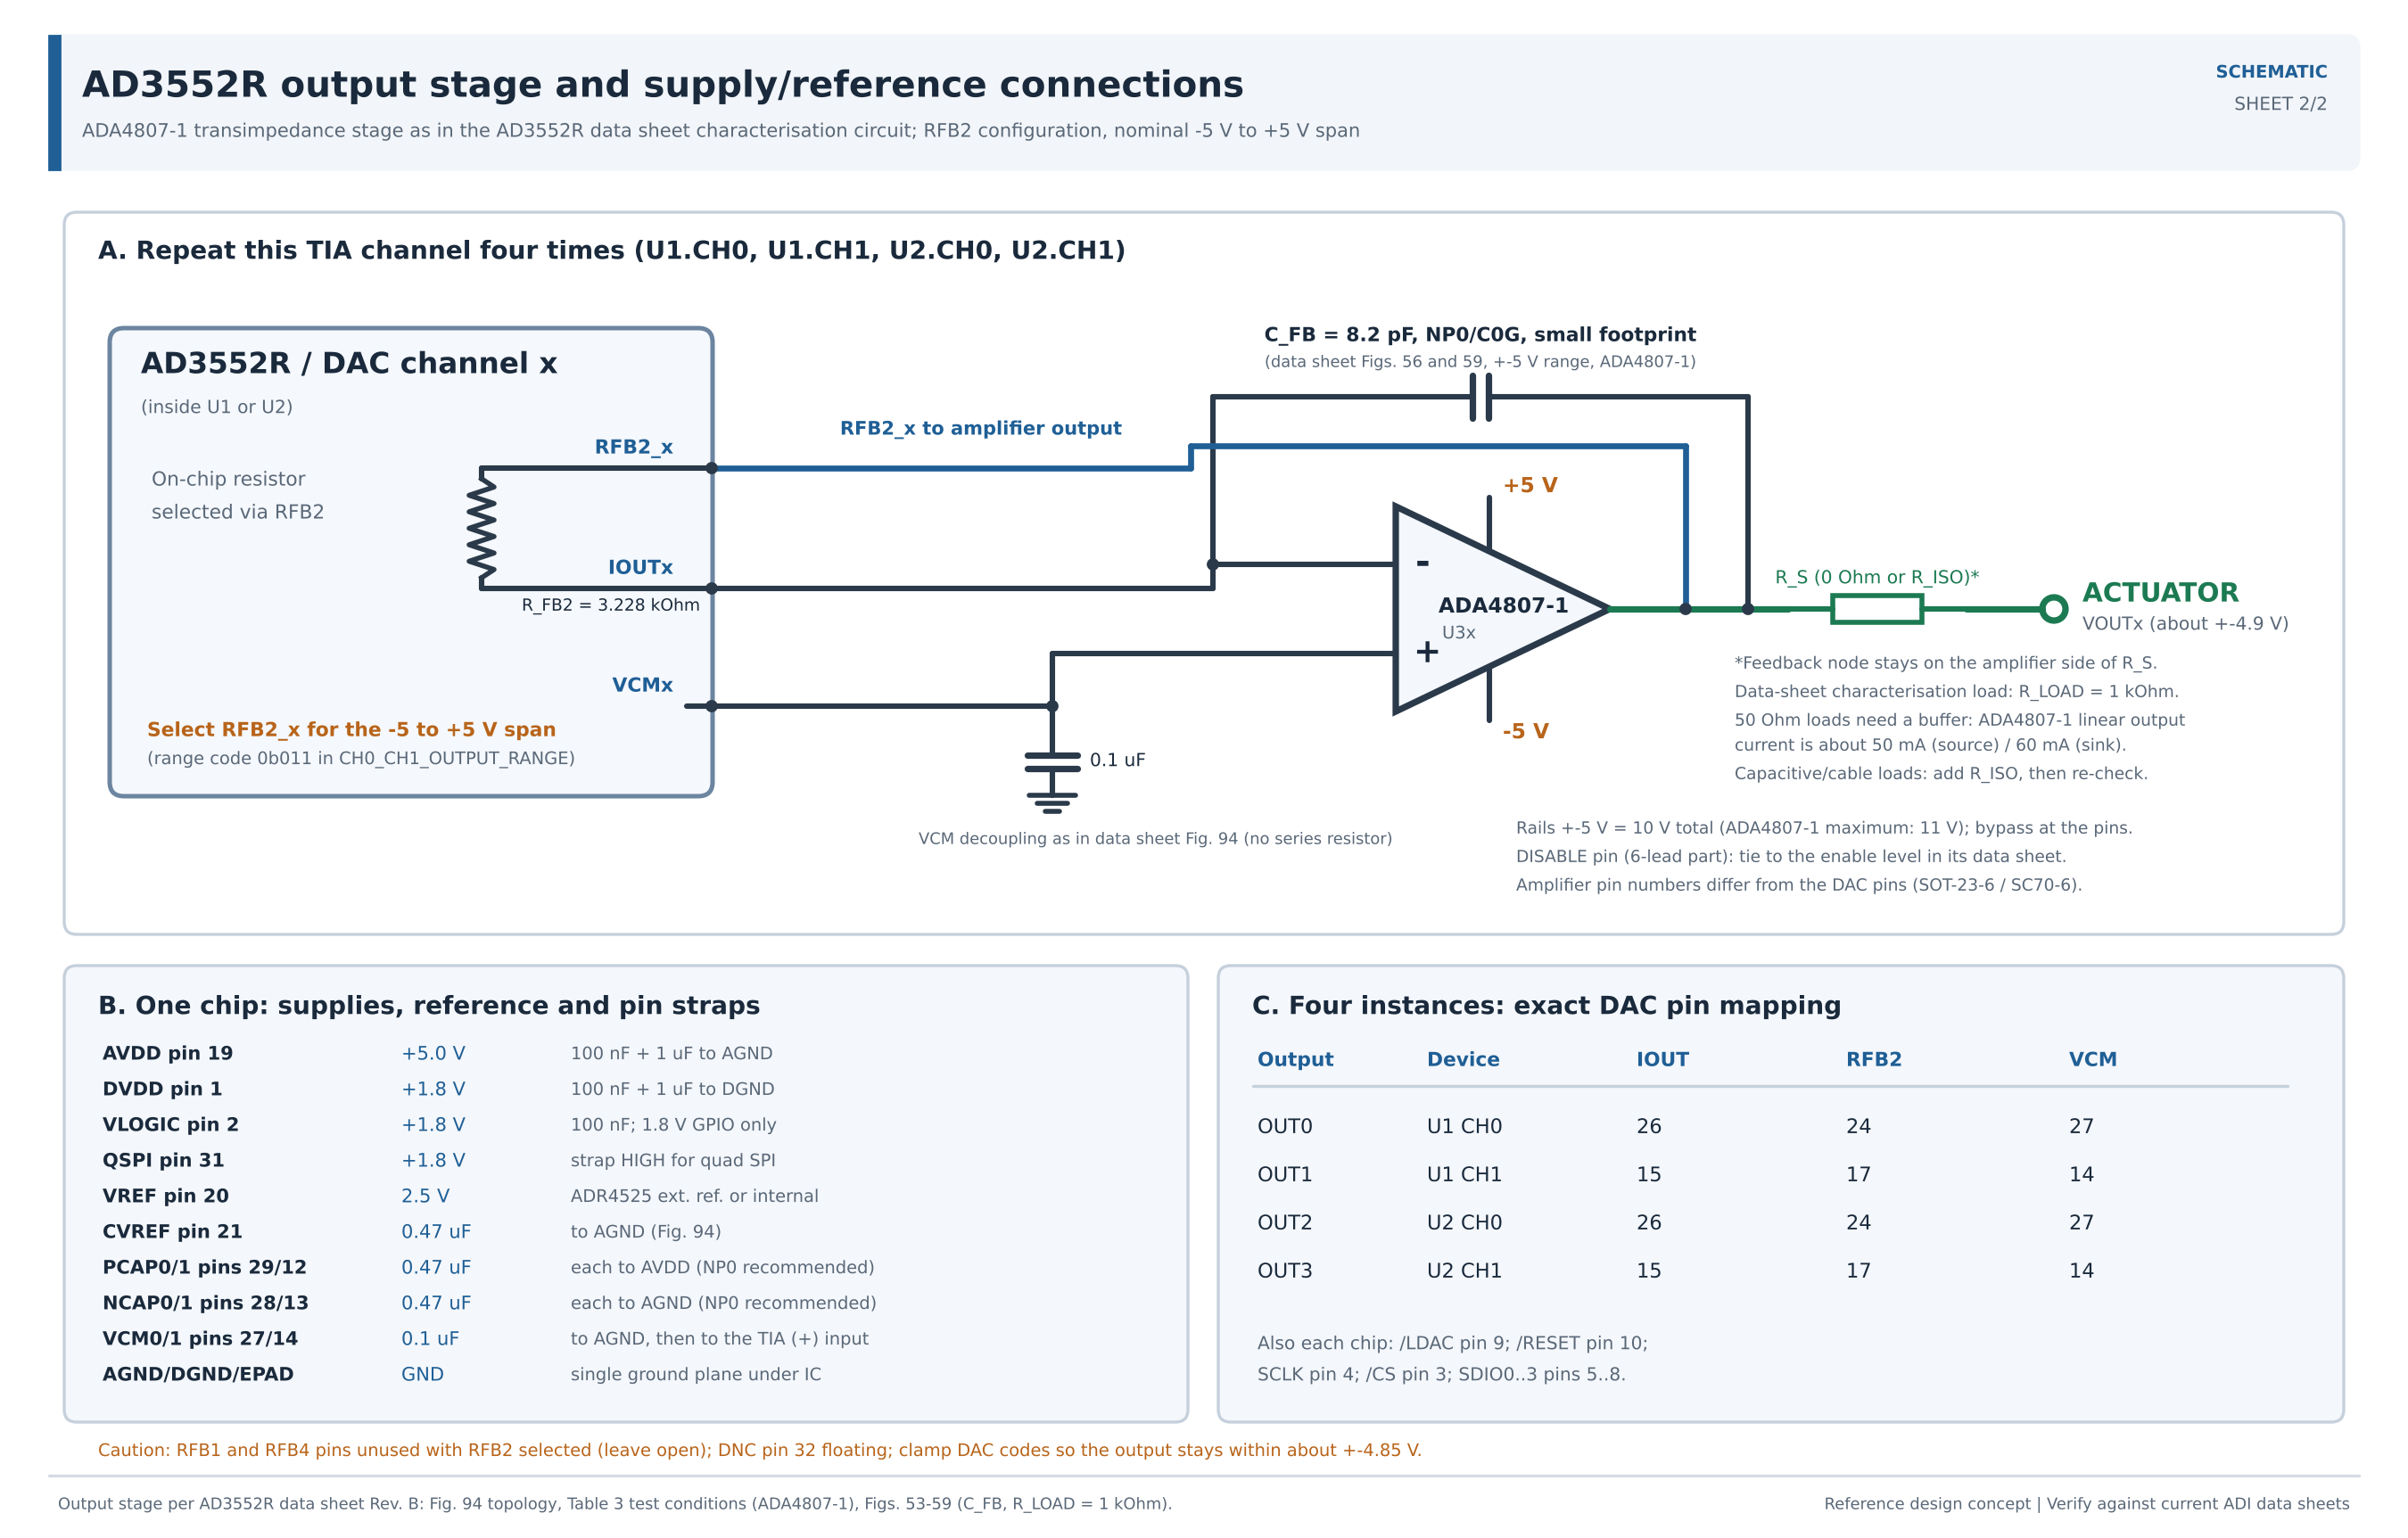

*Sheet 2: AD3552R current-to-voltage channel (ADA4807-1 reference circuit) and power/reference connections*

### One channel as an explicit electrical connection list

1. `IOUTx` (U1/U2, pin 26 or 15) -> **ADA4807-1 inverting (-) input**, with the shortest and thinnest practical trace. The data sheet's layout guidelines (p. 69) point out that parasitic capacitance on this line increases settling time and that it is a high-impedance node prone to pick-up.
2. `RFB2_x` (pin 24 or 17) -> **ADA4807-1 output, before any output series resistor**. This closes the feedback path through the DAC's on-chip **3.228125 kOhm** (nominal) resistor.
3. `VCMx` (pin 27 or 14) -> **ADA4807-1 non-inverting (+) input directly**, with **0.1 uF** from that node to ground (data sheet Figure 94). No series resistor: the 3.3 kOhm resistors in data sheet Figure 95 belong to the two-channels-into-one-amplifier configuration.
4. `C_FB` = **8.2 pF, NP0/C0G**, from the **inverting input to the amplifier output**: the value with which the data sheet characterises the +/-5 V range using the ADA4807-1 (Figures 56, 59). The data sheet asks for NP0 dielectric on capacitors in the output-voltage path and a small footprint for this one (pp. 68-69).
5. ADA4807-1 supply pins -> **+5 V and -5 V**, locally bypassed. The 6-lead ADA4807-1 also has a **DISABLE** pin: tie it to the enable level given in the ADA4807 data sheet, never leave it floating. Check the **specific package pinout** (SOT-23-6 or SC70-6): the DAC pin numbers do not apply to the amplifier.
6. Amplifier output -> **electrode-pair output stage of Section 5.1**: 49.9 Ohm `R_ISO+` to `J_x+`, and the unity-gain inverter, then 49.9 Ohm `R_ISO-` to `J_x-`. **The feedback node stays on the amplifier side of this resistor** unless the circuit is explicitly redesigned.

The fundamental transfer law (datasheet p. 27) is

$$V_{\mathrm{OUT}} = V_{\mathrm{CM}} - R_{\mathrm{FB}} I_{\mathrm{OUT}}.$$

The DAC's register-controlled bipolar offset and gain create a nominal $-5$ V to $+5$ V output with **RFB2** connected, despite $V_{CM}\approx 2.5$ V. The exact end points include roughly 3% overrange (-5.165 V / +5.166 V, Table 8). **With +/-5 V amplifier rails the ADA4807-1 output stops about 0.1 V short of each rail**, so the extreme codes cannot be reproduced: clamp commands in firmware to about +/-4.85 V, and calibrate rather than assume an ideal line.

**Potential design issue:** an optional 49.9 Ohm *series* resistor is shown in earlier drawings as a line-matching part. If the receiving instrument has a 50 Ohm input termination, there is substantial voltage division and a drive current the ADA4807-1 cannot supply (Section 11). It is **not** correct to promise +/-5 V at the actuator terminal merely because the DAC range is configured to +/-5 V.

### 5.1 Output stage for an electrode pair

Each output drives **a pair of electrodes in push-pull**: connector `J_x+` carries $+V_{OUTx}$ (the TIA output) and `J_x-` carries $-V_{OUTx}$ from a unity-gain inverter, so up to about **9.8 V appears across the pair**. Compared with driving one electrode against a grounded partner, this doubles the force per DAC volt, keeps the potential at the trap centre near zero (no static common-mode shift), and still needs only one DAC channel per axis, so three axes plus a spare fit on the four channels. A single-ended fallback is built in: leave the inverter off and fit a 0 Ohm link from `J_x-` to ground.

| Part (per channel) | Value | Why |
|---|---|---|
| Inverter U16-U19 | **ADA4807-1**, gain -1, same +/-5 V rails | Same amplifier, swing and rails as the TIA |
| $R_G$, $R_F$ | **2.49 kOhm, 0.1% thin film** | The data sheet characterises G = -1 with 499 Ohm, but that would draw 9.8 mA per resistor at full swing; 2.49 kOhm keeps all eight amplifiers at 24 mA per rail (Section 8.1) and loads the TIA more lightly than its 1 kOhm test load |
| $C_F$ across $R_F$ | **1.0 pF NP0** | Without it the input capacitance gives 35 degrees of phase margin and 4.4 dB of peaking; 1.0 pF gives 68 degrees, a flat response to 53 MHz and 4.3 ns of delay (cell below) |
| Non-inverting input | to ground, with a footprint for $R_B$ = 1.24 kOhm + 100 nF | Optional input-bias-current offset cancellation |
| $R_{ISO\pm}$ | **49.9 Ohm** at each amplifier output, outside the feedback loop | Isolates the amplifier from the cable capacitance (the ADA4807-1 overshoots 17% with only 15 pF directly) and **source-terminates the 50 Ohm coax**: the electrode is an open line end, so the wave doubles there to the full amplifier voltage and the reflection is absorbed at the source. No ringing, no DC current, no voltage division |
| Clamp | **BAV99** from each connector node to +5 V and -5 V | Stray charge and ESD from the chamber wiring; $R_{ISO}$ limits the diode current |
| Bleeder | **1 MOhm** from each connector node to ground | Defines the electrode potential when the amplifiers are off and drains accumulated charge |
| Connector | **SMA jack, 50 Ohm, vertical through-hole (Amphenol RF 132134)**, eight per board (`J4`-`J11`: OUT0+/-, ..., OUT3+/-) | Matches 50 Ohm coax and the Red Pitaya's own SMA inputs, is compact, and UHV SMA feedthroughs are standard parts (for example MDC 9252000: one pin, grounded shield, DN16CF flange). Place the jacks in +/- pairs at >= 10 mm pitch so that a torque wrench fits, and label each pair |

**Cabling.** Use 50 Ohm coax such as RG-316 (PTFE dielectric, about 96 pF/m and 4.8 ns/m) to the feedthroughs, keep the two cables of a pair together, and ground the shields at the board. Inside the vacuum, continue with vacuum-compatible coax (for example Kapton-insulated) to the electrodes. If the chamber has a multi-pin (D-sub) feedthrough instead of coaxial ones, run a twisted pair per axis; the 49.9 Ohm resistors then act only as isolation resistors.

**Effect on the loop.** For symmetric electrodes the field at the particle is proportional to $V_{x+} - V_{x-} = 2V_{OUTx}$, so the force coefficient per DAC volt doubles; calibrate it (N per volt of $V_{OUTx}$) with the pair connected. The inverter delays the negative electrode by about 4 ns, and the cable adds about 5 ns per metre to both: small next to the 26 ns TIA lag and the 64 ns sample period, and it can be included in the latency $d$ of Section 10.9.

In [ ]:
# Sheet 4: output stage for one electrode pair (repeat for OUT0-OUT3): push-pull drive through source-terminated coax
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon, Circle

fig, ax = plt.subplots(figsize=(13.5, 6.6))
ax.set_xlim(0, 13.5); ax.set_ylim(0, 6.6); ax.axis("off")
K = "#22303f"
def line(*pts, c=K, lw=1.4):
    xs, ys = zip(*pts); ax.plot(xs, ys, color=c, lw=lw, solid_capstyle="round")
def dot(x, y): ax.add_patch(Circle((x, y), 0.045, color=K, zorder=5))
def res(x0, y, x1, lab, val, vert=False):
    if not vert:
        line((x0, y), (x0 + 0.25, y)); line((x1 - 0.25, y), (x1, y))
        ax.add_patch(FancyBboxPatch((x0 + 0.25, y - 0.11), x1 - x0 - 0.5, 0.22, boxstyle="square,pad=0", fc="white", ec=K, lw=1.3))
        ax.text((x0 + x1) / 2, y + 0.2, lab, ha="center", fontsize=8, color="#7a4e10")
        ax.text((x0 + x1) / 2, y - 0.38, val, ha="center", fontsize=7.5, color="#33465a")
    else:
        line((x0, y), (x0, y - 0.25)); line((x0, x1 + 0.25), (x0, x1))
        ax.add_patch(FancyBboxPatch((x0 - 0.11, x1 + 0.25), 0.22, y - x1 - 0.5, boxstyle="square,pad=0", fc="white", ec=K, lw=1.3))
        ax.text(x0 + 0.18, (y + x1) / 2, f"{lab}\n{val}", fontsize=7.3, va="center", color="#33465a")
def cap(x, y0, y1, lab, horiz=False):
    if horiz:
        xm = (y0 + y1) / 2   # here y0, y1 are x-positions, x is the y-coordinate
        line((y0, x), (xm - 0.06, x)); line((xm + 0.06, x), (y1, x))
        line((xm - 0.06, x - 0.17), (xm - 0.06, x + 0.17)); line((xm + 0.06, x - 0.17), (xm + 0.06, x + 0.17))
        ax.text(xm, x + 0.22, lab, ha="center", fontsize=7.5, color="#7a4e10")
    else:
        ym = (y0 + y1) / 2
        line((x, y0), (x, ym + 0.06)); line((x, ym - 0.06), (x, y1))
        line((x - 0.17, ym + 0.06), (x + 0.17, ym + 0.06)); line((x - 0.17, ym - 0.06), (x + 0.17, ym - 0.06))
        ax.text(x + 0.22, ym, lab, fontsize=7.3, va="center", color="#33465a")
def gnd(x, y):
    line((x, y), (x, y - 0.12)); line((x - 0.15, y - 0.12), (x + 0.15, y - 0.12))
    line((x - 0.09, y - 0.17), (x + 0.09, y - 0.17)); line((x - 0.04, y - 0.22), (x + 0.04, y - 0.22))
def opamp(x, y, name, w=0.95, h=1.0):
    ax.add_patch(Polygon([(x, y - h / 2), (x, y + h / 2), (x + w, y)], closed=True, fc="#fff1dc", ec=K, lw=1.4))
    ax.text(x + 0.12, y + 0.24, "-", fontsize=11, va="center"); ax.text(x + 0.12, y - 0.24, "+", fontsize=10, va="center")
    ax.text(x + w * 0.5, y - h / 2 - 0.45, name, ha="center", fontsize=7.6, color="#7a4e10")
def clamp(x, y, lab):
    """BAV99 to +/-5 V (drawn as a box) and 1 MOhm bleeder to ground at the connector node."""
    ax.add_patch(FancyBboxPatch((x - 0.36, y + 0.25), 0.72, 0.42, boxstyle="round,pad=0.02", fc="#eef3fa", ec=K, lw=1))
    ax.text(x, y + 0.46, "BAV99\nto +/-5 V", ha="center", va="center", fontsize=6.6)
    line((x, y), (x, y + 0.25)); res(x, y, y - 1.05, "", "", vert=True); gnd(x, y - 1.05)
    ax.text(x + 0.2, y - 0.52, "1 M", fontsize=7, va="center")
def sma(x, y, lab):
    ax.add_patch(Circle((x, y), 0.2, fc="#f6e3b4", ec=K, lw=1.3)); ax.add_patch(Circle((x, y), 0.06, color=K))
    ax.text(x + 0.3, y, lab, va="center", fontsize=8.6, weight="bold", color="#1d4d31")
    line((x, y - 0.2), (x, y - 0.42)); gnd(x, y - 0.42)

# TIA (from Section 5) as a block
ax.add_patch(FancyBboxPatch((0.2, 3.65), 2.3, 1.3, boxstyle="round,pad=0.03", fc="#e8f5ee", ec=K, lw=1.2))
ax.text(1.35, 4.62, "ADA4807-1 TIA (U3-U6)", ha="center", fontsize=8.4, weight="bold")
ax.text(1.35, 4.15, "IOUTx, RFB2_x, VCMx,\nC_FB = 8.2 pF (Section 5)", ha="center", fontsize=7.4, color="#33465a")
line((2.5, 4.3), (3.6, 4.3)); dot(3.6, 4.3); ax.text(2.62, 4.45, "V_OUTx", fontsize=8, color="#1f5f99")
# + path
line((3.6, 4.3), (3.6, 5.6)); res(3.6, 5.6, 6.6, "R_ISO+", "49.9 Ohm"); dot(8.6, 5.6)
line((6.6, 5.6), (11.2, 5.6)); clamp(8.6, 5.6, "+"); sma(11.4, 5.6, "J_x+  (OUTx+)")
# inverter
line((3.6, 4.3), (3.6, 3.2)); res(3.6, 3.2, 5.2, "R_G", "2.49 k, 0.1%"); dot(5.2, 3.2)
opamp(5.5, 2.95, "U16-U19 ADA4807-1  (G = -1)")
line((5.2, 3.2), (5.5, 3.2)); line((5.5, 2.7), (4.95, 2.7)); line((4.95, 2.7), (4.95, 2.5)); gnd(4.95, 2.5)
ax.text(4.3, 2.35, "(+) to GND\n(R_B footprint)", fontsize=6.8, color="#5a6b7d", ha="center")
line((5.2, 3.2), (5.2, 4.6)); line((6.9, 2.95), (6.9, 4.6))
res(5.2, 4.0, 6.9, "R_F", "2.49 k, 0.1%")
cap(4.6, 5.2, 6.9, "C_F 1.0 pF NP0", horiz=True)
line((6.45, 2.95), (6.9, 2.95)); dot(6.9, 2.95)
res(6.9, 2.95, 8.4, "R_ISO-", "49.9 Ohm"); line((8.4, 2.95), (8.6, 2.95)); dot(8.6, 2.95)
line((8.6, 2.95), (11.2, 2.95)); clamp(8.6, 2.95, "-"); sma(11.4, 2.95, "J_x-  (OUTx-)")
ax.text(9.0, 1.85, "SE option: omit U16-U19 and fit a 0 Ohm link\nfrom J_x- to GND (partner electrode grounded)", fontsize=7, color="#5a6b7d")
# cable and electrodes
ax.text(9.9, 0.65, "50 Ohm coax (e.g. RG-316) to the chamber's SMA feedthroughs;\n"
        "electrodes are open (high-impedance) line ends, so 49.9 Ohm source\n"
        "termination gives the full voltage at the electrode without ringing", fontsize=7.4, color="#33465a", ha="center")
ax.text(11.6, 4.35, "V_x+ = +V_OUTx\nV_x- = -V_OUTx\nacross the pair: 2 V_OUTx\n(up to about 9.8 V)", fontsize=8, color="#1f5f99", ha="left")
ax.set_title("Sheet 4: output stage for one electrode pair (x = 0..3): push-pull through source-terminated 50 Ohm coax", fontsize=11.5)
plt.show()

In [ ]:
# Electrode-pair output stage: inverter stability, timing match between the two electrodes, cable and current budget
import numpy as np
import matplotlib.pyplot as plt

GBW, A0 = 180e6, 10 ** 6.5                 # ADA4807-1 single-pole model (as in Section 7.1)
wt = 2 * np.pi * GBW; wp = wt / A0
RF = RG = 2.49e3
C_in = 1e-12 + 1e-12 + 1.5e-12            # common-mode + differential input capacitance (data sheet) + layout allowance

def inverter(f, C_F):
    s = 2j * np.pi * np.asarray(f, float)
    A = A0 * wp / (s + wp)
    Zf = RF / (1 + s * RF * C_F)
    Zg_par = RG / (1 + s * RG * C_in)                      # R_G in parallel with the input capacitance, as seen by Zf
    beta = Zg_par / (Zg_par + Zf)
    T = A * beta
    H = -(Zf / RG) * T / (1 + T)                           # ideal inverting gain times the loop's T / (1 + T)
    return H, T

f = np.logspace(5, 9.5, 4000)
print(f"Inverter (G = -1, R_F = R_G = {RF/1e3:.2f} kOhm, C_in = {C_in*1e12:.1f} pF):")
print("  C_F    phase margin   peaking   -3 dB BW   delay at 1 MHz")
res = {}
for C_F in (0.0, 1.0e-12, 2.2e-12, 3.3e-12):
    H, T = inverter(f, C_F)
    k = np.argmin(np.abs(np.abs(T) - 1)); pm = 180 + np.degrees(np.angle(T[k]))
    mag = np.abs(H) / np.abs(H[0])
    bw = f[np.argmax(mag < 1 / np.sqrt(2))]
    ph = np.unwrap(np.angle(-H)); tau = -np.gradient(ph, 2 * np.pi * f)[np.argmin(np.abs(f - 1e6))]
    res[C_F] = (H, pm)
    print(f"  {C_F*1e12:3.1f} pF   {pm:6.1f} deg    {20*np.log10(mag.max()):5.2f} dB   {bw/1e6:6.1f} MHz   {tau*1e9:5.2f} ns")

# + and - electrodes: the + side has no inverter, so the pair is skewed by the inverter's delay
C_F_SEL = 1.0e-12
H, _ = inverter([1e6], C_F_SEL)
skew = -np.angle(-H[0]) / (2 * np.pi * 1e6)
print(f"\nChosen C_F = {C_F_SEL*1e12:.1f} pF: the - electrode lags the + electrode by {skew*1e9:.1f} ns, a brief common-mode"
      f" step at each update, {skew / 64e-9 * 100:.0f}% of the 64 ns sample period")

# Cable: RG-316, velocity factor 0.695 -> about 4.8 ns/m; open (electrode) end, 49.9 Ohm source termination
for L in (0.5, 1.0, 2.0):
    print(f"  {L:.1f} m of RG-316: one-way delay {L / (0.695 * 3e8) * 1e9:4.1f} ns, about {96 * L:.0f} pF")

# Rail current: 8 amplifiers per rail, capacitive electrodes (no DC current), 1 MOhm bleeders
Iq, Vmax = 1.0e-3, 4.9
I_tia = Iq + Vmax / RG + Vmax / 1e6              # quiescent + inverter input resistor + bleeder
I_inv = Iq + Vmax / RF + Vmax / 1e6              # quiescent + feedback resistor + bleeder
I_rail = 4 * (I_tia + I_inv)
print(f"\nDC current per amplifier rail, all four pairs at full swing: {I_rail*1e3:.1f} mA of the LTC3260's 50 mA")
SR, C_cable = 180e6, 2 * 96e-12
print(f"Slewing current into 2 m of coax at the 180 V/us slew rate: {C_cable * SR * 1e3:.0f} mA per output, for < 60 ns "
      "(from the rail capacitors; the ADA4807-1 sources 50 mA, sinks 60 mA linearly)")

fig, ax = plt.subplots(figsize=(9, 3.3))
for C_F, (H, pm) in res.items():
    ax.semilogx(f / 1e6, 20 * np.log10(np.abs(H) / np.abs(H[0])), label=f"C_F = {C_F*1e12:.1f} pF (PM {pm:.0f} deg)")
ax.set(xlabel="frequency (MHz)", ylabel="|V_x- / V_OUTx| (dB)", ylim=(-12, 6),
       title="Unity-gain inverter for the second electrode: feedback capacitor and peaking")
ax.grid(alpha=.3, which="both"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. DAC range registers and the voltage transfer function

In the datasheet's **predefined output-range** table, `0b011` selects **-5 V to +5 V** *when* the selected channel's output amplifier feedback uses `RFB2_x`. The upper nibble of the `CH0_CH1_OUTPUT_RANGE` register is for channel 1 and the lower nibble for channel 0, so a natural starting write is:

`CH0_CH1_OUTPUT_RANGE` at address **0x19** <- **0x33** (both channels set to 0b011).

This is a **register-level starting point**, not an entire verified firmware driver. The external/internal reference selection, channel state, LDAC masks, data-address ordering, and error/status bits also require deliberate configuration. Use the current datasheet register definitions rather than copying an undocumented register dump.

For first-pass scaling, use $\Delta V\approx(10\,\mathrm{V})/2^{16}$; with a bipolar ideal midscale mapping, $V\approx -5 + 10 D/(2^{16}-1)$ for unsigned code $D$. **This pedagogical formula is not the exact AD3552R transfer function**: the datasheet's actual offset/gain terms and overrange alter endpoints (its p. 27 equation should be used for an accurate code-to-voltage model).

In [ ]:
# Simple idealised code-to-voltage conversion to size the feedback signals.
Vmin, Vmax = -5.0, 5.0
n_bits = 16
lsb = (Vmax - Vmin) / 2**n_bits
codes = np.array([0, 16384, 32768, 49152, 65535])
volts = Vmin + codes * (Vmax - Vmin) / 65535
print(f'Ideal +/-5 V LSB = {lsb*1e6:.3f} uV, rms quantization noise = {lsb/np.sqrt(12)*1e6:.2f} uV')
for d, v in zip(codes, volts):
    print(f'  code 0x{d:04X} ({d:5d}) -> about {v:+.5f} V')
fig,ax=plt.subplots(figsize=(9,3.3))
ax.plot(np.linspace(0,65535,500),Vmin+(Vmax-Vmin)*np.linspace(0,65535,500)/65535,lw=2)
ax.scatter(codes,volts,zorder=3)
ax.set(xlabel='Unsigned 16-bit DAC code',ylabel='Approximate output voltage (V)',
       title='Ideal code-voltage map (not the calibrated AD3552R end points)')
ax.grid(alpha=.25)
plt.show()

## 7. Current-output DAC intuition and compensation

The DAC uses a programmable current source/sink rather than a direct voltage driver. The amplifier holds its inverting input close to the `VCM` level and converts DAC current to a voltage via the internal selected feedback resistor. This is why a simple output-voltage buffer is **not** an adequate replacement for the TIA.

- `RFB1` nominal **1.610938 kOhm**: used for the 2.5 V and 5 V spans.
- `RFB2` nominal **3.228125 kOhm**: used for the **10 V** and **+/-5 V** spans.
- `RFB4` nominal **6.488125 kOhm**: used for the **+/-10 V** span.

**Why the feedback capacitor is needed.** The amplifier sees the DAC's output capacitance, its own input capacitance and the layout capacitance at its inverting input, $C_{in}$, in series with the feedback resistor. Without $C_{FB}$ this forms a pole at $1/(R_FC_{in})$, far below the amplifier's crossover frequency, which eats almost all of the loop's phase margin, so the stage rings or oscillates. $C_{FB}$ adds a zero at $1/(R_FC_{FB})$ that restores the phase. The price is a dominant time constant $R_FC_{FB}$: 26 ns for RFB2 with 8.2 pF.

**The reference values.** The data sheet characterises the ADA4807-1 with **8.2 pF** (2.5 V, 5 V, ±5 V ranges) and **6.8 pF** (10 V range), R_LOAD = 1 kOhm (Figures 53-59). Those are the values used here. A smaller capacitor would be faster but is outside the characterised conditions. **Do not place an arbitrarily large capacitor across the TIA** in a time-critical LQG loop: every extra picofarad slows the actuator by about 3 ns (R_F = 3.2 kOhm).

The ADA4807-1's 180 MHz bandwidth does **not** mean the DAC+TIA settles in a few nanoseconds: the stage is set by $R_FC_{FB}$ and, for large steps, by the slew rate. The next subsection quantifies this.

### 7.1 A numerical model of the ADA4807-1 stage

A single-pole model of the op-amp, $A(s)=A_0\omega_p/(s+\omega_p)$ with gain-bandwidth $\omega_t=A_0\omega_p$, closed around $Z_F=R_F\,\|\,C_{FB}$ with $C_{in}$ at the inverting node, gives the transfer function from the voltage the DAC code asks for, $V_{cmd}=-R_FI_{OUT}$, to the actual output:

$$
H(s)=\frac{V_{OUT}}{V_{cmd}}=\frac{1}{(1+sR_FC_{FB})+\big(1+sR_F(C_{FB}+C_{in})\big)\dfrac{s+\omega_p}{\omega_t}} .
$$

The loop gain is $T=A\beta$ with $\beta=(1+sR_FC_{FB})/(1+sR_F(C_{FB}+C_{in}))$. Large steps are additionally limited by the slew rate, so the code below also integrates the circuit equations with the output rate clipped to ±SR and the output clamped to the swing.

Two inputs are **assumptions**, because neither data sheet states them: the gain-bandwidth product (taken as the 180 MHz unity-gain bandwidth) and $C_{in}$ (10 pF nominal: 2 pF amplifier input plus the DAC pin and layout). The model is checked against the one configuration for which the data sheet gives settling times (0-5 V range, RFB1, 8.2 pF).

In [ ]:
# Self-contained TIA model (the same equations as pylqg.actuator in the LQG notebook)
RFB = {"RFB1": 1610.938, "RFB2": 3228.125}
A0 = 10 ** (130 / 20)                       # ADA4807-1 open-loop gain, 130 dB typ

def H_den(RF, CF, Cin, GBW):
    wt = 2 * np.pi * GBW; wp = wt / A0
    return np.polyadd([RF * CF, 1.0], np.polymul([RF * (CF + Cin), 1.0], [1.0, wp]) / wt)

def freq_metrics(RF, CF, Cin, GBW=180e6):
    f = np.logspace(3, 11, 40001); s = 2j * np.pi * f
    h = 1 / np.polyval(H_den(RF, CF, Cin, GBW), s); h /= abs(h[0])
    wt = 2 * np.pi * GBW
    T = wt / (s + wt / A0) * (1 + s * RF * CF) / (1 + s * RF * (CF + Cin))
    i = np.argmax(np.abs(T) < 1)
    return f[np.argmax(np.abs(h) < 1 / np.sqrt(2))], 20 * np.log10(np.abs(h).max()), 180 + np.degrees(np.angle(T[i]))

def step(RF, CF, Cin, v0, v1, SR=np.inf, vmin=-np.inf, vmax=np.inf, GBW=180e6, t_end=600e-9, dt=0.05e-9):
    """Large-signal step: RK4 on (v_minus, v_out) with slew-rate and swing limits."""
    wt = 2 * np.pi * GBW; wp = wt / A0
    def rhs(x, vcmd):
        vm, vo = x
        dvo = np.clip(-wt * vm - wp * vo, -SR, SR)
        if (vo >= vmax and dvo > 0) or (vo <= vmin and dvo < 0): dvo = 0.0
        dvm = (-vcmd / RF - (vm - vo) / RF + CF * dvo) / (Cin + CF)
        return np.array([dvm, dvo])
    x = np.array([-v0 / A0, v0]); t = np.arange(0, t_end, dt); y = np.empty(len(t))
    for k in range(len(t)):
        y[k] = x[1]
        k1 = rhs(x, v1); k2 = rhs(x + dt / 2 * k1, v1); k3 = rhs(x + dt / 2 * k2, v1); k4 = rhs(x + dt * k3, v1)
        x = x + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4); x[1] = min(max(x[1], vmin), vmax)
    return t, y

def settle(t, y, v0, v1, tol):
    bad = np.where(np.abs(y - v1) > tol * abs(v1 - v0))[0]
    return t[min(bad[-1] + 1, len(t) - 1)] if len(bad) else 0.0

print("Small-signal behaviour of the +/-5 V stage (RFB2) versus C_FB and the unknown C_in:")
print(f"{'C_FB':>6s} {'C_in':>5s} {'-3 dB':>9s} {'peaking':>8s} {'phase margin':>13s}")
for CF in (0.0, 4.7e-12, 8.2e-12):
    for Cin in (5e-12, 10e-12, 20e-12):
        f3, pk, pm = freq_metrics(RFB["RFB2"], CF, Cin)
        print(f"{CF*1e12:4.1f}pF {Cin*1e12:3.0f}pF {f3/1e6:7.1f}MHz {pk:6.1f}dB {pm:11.1f}deg")

print("\nCheck against the data sheet (0-5 V range, RFB1, C_FB = 8.2 pF, 2 V step, system slew ~150 V/us):")
t, y = step(RFB["RFB1"], 8.2e-12, 10e-12, 1.35, 3.35, SR=150e6)
print(f"   model: {settle(t, y, 1.35, 3.35, 1e-2)*1e9:.0f} ns to 1%, {settle(t, y, 1.35, 3.35, 1e-3)*1e9:.0f} ns to 0.1%"
      "   | data sheet Table 3: 75 ns, 100 ns")
print("\nThis design (+/-5 V range, RFB2, C_FB = 8.2 pF, ~180 V/us, +/-5 V rails -> swing +/-4.9 V):")
res = {}
for v0, v1 in ((0.0, 0.06), (-1.0, 1.0), (-4.5, 4.5)):
    t, y = step(RFB["RFB2"], 8.2e-12, 10e-12, v0, v1, SR=180e6, vmin=-4.9, vmax=4.9)
    res[(v0, v1)] = (t, y)
    print(f"   {v1 - v0:5.2f} V step: {settle(t, y, v0, v1, 1e-2)*1e9:4.0f} ns to 1%, {settle(t, y, v0, v1, 1e-3)*1e9:4.0f} ns to 0.1%")
t, y = res[(0.0, 0.06)]                                   # linear (unslewed) response
peak_slope = np.max(np.diff(y)) / (t[1] - t[0]) / 0.06    # peak dV/dt per volt of step
print(f"   R_F*C_FB = {RFB['RFB2']*8.2e-12*1e9:.1f} ns; the linear response's peak slope is {peak_slope/1e6:.0f} V/us per volt,")
print(f"   so only steps larger than about {180e6/peak_slope:.1f} V reach the 180 V/us slew limit")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for CF, col in ((0.0, "C3"), (8.2e-12, "C0")):
    t, y = step(RFB["RFB2"], CF, 10e-12, 0.0, 0.1, t_end=400e-9, dt=0.05e-9)
    ax[0].plot(t * 1e9, y / 0.1, col, label=f"C_FB = {CF*1e12:.1f} pF" + ("  (reference)" if CF else "  (no capacitor)"))
ax[0].set(xlabel="time (ns)", ylabel="normalised output", title="Small-signal step, RFB2, C_in = 10 pF"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.25)
for (v0, v1), (t, y) in res.items():
    ax[1].plot(t * 1e9, (y - v0) / (v1 - v0), label=f"{v1 - v0:.2f} V step")
ax[1].set(xlabel="time (ns)", ylabel="(V_OUT - V_0) / step", title="ADA4807-1 reference stage, +/-5 V range"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.25)
plt.tight_layout(); plt.show()

**What the model says.**

* **Without C_FB the stage is nearly unstable**: 7-13 degrees of phase margin and 13-19 dB of peaking, so the step rings for hundreds of nanoseconds. With the manufacturer's **8.2 pF** the phase margin is **85-89 degrees** whatever the unknown $C_{in}$ (5-20 pF). The response is then essentially first order, with $R_FC_{FB}$ = 26 ns and a -3 dB bandwidth of about 6.3 MHz.
* **The model reproduces the data sheet's large-signal settling** (0-5 V range: about 57 ns / 85 ns against 75 ns / 100 ns) to within 15-25%. It is *pessimistic* for small steps: the data sheet's 60 mV figure (15 ns to 1%) is faster than any linear stage with a 14 ns time constant can be.
* **In the ±5 V range the stage settles in about 180 ns to 0.1%, not 100 ns.** The 100 ns headline belongs to the 0-5 V range with its half-size feedback resistor. Section 9's timing budget uses the ±5 V figure.
* **Slewing is rare.** The linear response is already slower than 180 V/us for any step below about 5.7 V, i.e. more than half of the ±4.9 V output range; the 9 V step above slews only briefly. In closed loop the LQG commands are tens of millivolts (LQG notebook, Section 12.7), so the large-signal limit that matters in practice is the **output swing**.

## 8. Supplies, reference, decoupling, and grounding

### Supply tree (each AD3552R)

| Rail / pin | Nominal | Decoupling (data sheet Figure 94 unless noted) | Notes |
|---|---:|---|---|
| `AVDD` (19) | +5.0 V | 1 uF + 100 nF to ground (Figure 94 shows one capacitor without a value) | Quiet analog rail: its high-frequency noise matters most (data sheet) |
| `DVDD` (1) | +1.8 V | 1 uF (Figure 94), plus 100 nF at the pin | Bursty current that follows the SPI traffic: own ferrite branch (Section 8.1) |
| `VLOGIC` (2) | +1.8 V | 0.1 uF | Matches the translators' 1.8 V side (Section 10.2) |
| `QSPI` (31) | strap | 1 kOhm to `VLOGIC` | High selects quad SPI |
| `CVREF` (21) | reference decoupling | 0.47 uF to AGND | High-K dielectric acceptable (constant voltage) |
| `PCAP0/1` (29/12) | noise-control node | 0.47 uF each to `AVDD`, **NP0** | In the output-voltage path: NP0 per the data sheet |
| `NCAP0/1` (28/13) | noise-control node | 0.47 uF each to AGND, **NP0** | In the output-voltage path: NP0 per the data sheet |
| `VCM0/1` (27/14) | 2.5 V common mode | 0.1 uF each to AGND | High-K dielectric acceptable |
| `VREF` (20) | 2.5 V | External ADR4525 example | Configure reference select appropriately |
| `AGND/DGND/EPAD` | 0 V | Low-impedance common plane | Datasheet recommends AGND and DGND together under device |

The datasheet Figure 94 is the authority for the precise arrangement of the decoupling caps. Its comments on C0G/NP0 dielectric for noise-control caps are important: real large-value C0G capacitors can be expensive or difficult to procure, so package/availability must be checked rather than blindly specifying a part.

### Supply tree (each ADA4807-1)

- Rails: **+5 V and -5 V** (10 V total), made on the board from +12 V by an LTC3260 (Section 8.1). The ADA4807-1's total supply range is 2.7 V to 11 V, so the +/-12 V rails of the earlier AD8065 concept **must not** be used, and +/-5 V keeps a 1 V margin to the limit, which also covers supply tolerances and transients.
- With +/-5 V rails the rail-to-rail output reaches about +/-4.9 V into 1 kOhm. That covers the nominal +/-5 V span except its outer ~3%; clamp commands in firmware to about +/-4.85 V.
- Each amplifier draws about 1 mA quiescent; four of them are negligible for the rails. Their output current into the load is not (Section 11).
- Place local high-frequency bypass capacitors very close to the amplifier supply pins; use appropriate bulk capacitance for the board.
- Tie each amplifier's **DISABLE** pin (6-lead package) to its enable level.
- A high-impedance load is the safe starting assumption; a 50 Ohm terminated line requires a **separate line driver**.

### Reference choice

An **external ADR4525** is an optional low-noise reference choice, but the AD3552R also contains a 2.5 V internal reference. If an external reference is used, program the reference selection correctly. The `VREF` pin is used differently in internal vs external mode; it must not be tied to two active voltage sources.

### 8.1 Power supply from a single +12 V input

The board takes **one +12 V input** and makes every rail itself. The amplifier rails stay **bipolar**: in levitation experiments the feedback force is applied through electrodes to a charged particle, with the partner electrode or the optics mount grounded, so the drive must swing both ways about 0 V. A unipolar output centred on 2.5 V would put a static force on the particle.

| Rail | Regulator | Why this part |
|---|---|---|
| `AVDD` +5.0 V (both DACs) | **TPS7A4901** linear regulator straight from +12 V; $V_{out} = V_{FB(nom)}\,(1 + R_1/R_2)$ with $V_{FB(nom)}$ = 1.185 V, $R_2$ = 100 kOhm (the data sheet's choice) and $R_1$ = 324 kOhm: 5.02 V, within the 4.75-5.25 V `AVDD` range including the 2.5% overall accuracy | 3-35 V input (36 V absolute), 150 mA, 21 uV rms at 5 V (10 Hz-100 kHz, with 10 nF noise-reduction and feed-forward capacitors), 72 dB PSRR at 120 Hz and > 52 dB from 10 Hz to 400 kHz. The AD3552R data sheet singles out `AVDD`'s high-frequency noise, so no switching converter is in its path |
| +/-5.0 V (eight ADA4807-1: four TIAs and four electrode inverters) | **LTC3260**: inverting charge pump (+12 V -> about -10.8 V) followed by its own LDO+ and LDO-; $V = \pm 1.2\,\mathrm{V}\,(1 + R_1/R_2)$ with 316 kOhm / 100 kOhm (+/-4.99 V) | One IC makes both rails: 4.5-32 V input, 50 mA per LDO, 100 uV rms with 10 nF bypass. `MODE` low and `RT` grounded: constant 500 kHz, above the 100 kHz mechanical band (Burst Mode would put load-dependent ripple at low frequencies) |
| 2.5 V intermediate | **AP63201** buck, forced PWM at 500 kHz; 131 kOhm / 62 kOhm, 3.3 uH, 10 uF in, 2 x 22 uF out, 100 nF bootstrap, 100 pF feed-forward (data sheet Table 1) | 3.8-32 V input, 2 A. Saves about 1 W against a linear drop from 12 V to 1.8 V |
| 1.8 V: `DVDD`, `VLOGIC`, translator `VCCB` | **TLV75518P** LDO (500 mA, SOT-23-5) from the 2.5 V rail, then a ferrite bead and 1 uF to each `DVDD` pin, each `VLOGIC` pin and the translators | Cleans the buck's ripple; separate branches keep the bursty `DVDD` current (data sheet) out of `VLOGIC`. One source for `DVDD` and `VLOGIC` also keeps `VLOGIC` below `DVDD` + 0.3 V (absolute maximum) |
| Input | 2.1 mm barrel jack, 0.5 A-hold polyfuse, 40 V / 2 A Schottky in series (reverse polarity), SMAJ15A TVS, 47 uF electrolytic + 10 uF ceramic | The three regulators on the +12 V input are rated to at least 35 V, above the TVS clamp |

**LTC3260 parts** (data sheet Rev. B; its typical-performance conditions and front-page circuit): flying capacitor 1 uF (needed for the full rated current), 10 uF each on `VIN`, `VOUT`, `LDO+` and `LDO-`, all low-ESR X7R/X5R ceramics rated 25 V so that each keeps at least 2 uF under bias; 10 nF from `BYP+` and `BYP-` to ground; `C_ADJ-` = 10 pF from `LDO-` to `ADJ-`, in parallel with the top divider resistor (Figure 3; 2-22 pF may be tried for transient response); `MODE` and `RT` to ground (constant 450-550 kHz); exposed pad soldered to the ground plane. Keep the `C+`/`C-` flying-capacitor nodes short and away from the analog circuitry. Pinout (MSOP-16E): `EN+` 1, `RT` 2, `BYP-` 3, `ADJ-` 4, `LDO-` 5, `VOUT` 6, `C-` 7, `NC` 8-9, `C+` 10, `VIN` 11, `LDO+` 12, `EN-` 13, `MODE` 14, `ADJ+` 15, `BYP+` 16. **TPS7A4901** (data sheet SBVS121E, Figure 29 "maximum AC performance"): 10 uF X7R on `IN` and `OUT` (at least 2.2 uF and ESR < 200 mOhm for stability), 10 nF from `NR/SS` to ground, 10 nF feed-forward from `OUT` to `FB`, all within 10 mm on the same side of the board without vias; `EN` (pin 5) tied to `IN` (allowed, $V_{EN} \le V_{IN}$; never left floating); `DNC` (pin 7) left unconnected; `NC` (pin 3) open or grounded; `GND` and the PowerPAD to the ground plane through several vias. The divider draws 11.8 uA, above the 5 uA needed for no-load stability. Pinout (HVSSOP-8): `OUT` 1, `FB` 2, `NC` 3, `GND` 4, `EN` 5, `NR/SS` 6, `DNC` 7, `IN` 8.

**Start-up order.** The AD3552R has no sequencing restriction, but its data sheet recommends `AVDD`, then `DVDD`, then `VLOGIC` to minimise the power-up glitch; the amplifiers should come last, while `RESET_N` (pulled low) holds both DACs in reset with `IOUT` and `VCM` at 0 V. The enables give exactly that: the TPS7A4901 starts with the +12 V input and ramps over its 14 ms soft-start (1.4 ms per nF of `NR/SS` capacitance); the AP63201's `EN` comes from `AVDD` through 100 kOhm / 36 kOhm, so the buck starts once `AVDD` passes 4.34-4.65 V; the TLV75518P follows the 2.5 V rail, bringing `DVDD` and `VLOGIC` up together; and the LTC3260's `EN+` and `EN-` connect to the 2.5 V rail, above their 2.0 V maximum threshold, so the +/-5 V rails start last.

**Layout.** Put the input protection, the buck and the charge pump at the input edge of the board, away from the TIAs and the reference. Keep the charge pump's flying-capacitor loop and the buck's switching loop small. Feed each regulator from the input bulk capacitor on its own trace (or through a ferrite) so that the buck's input ripple current does not flow under the analog regulators, and keep one continuous ground plane.

In [ ]:
# Power tree from a single +12 V input (bipolar +/-5 V amplifier rails generated on the board)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13.5, 6.8))
ax.set_xlim(0, 13.5); ax.set_ylim(0, 6.8); ax.axis("off")
def blk(x, y, w, h, title, body, fc, ec="#4b6075"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.08", fc=fc, ec=ec, lw=1.1))
    ax.text(x + w / 2, y + h - 0.1, title, ha="center", va="top", fontsize=8.8, weight="bold", color="#17283b")
    ax.text(x + w / 2, y + h - 0.42, body, ha="center", va="top", fontsize=7.1, color="#33465a", linespacing=1.35)
def wire(pts, lab="", c="#3b526e", at=0.5, dy=0.1):
    xs, ys = zip(*pts)
    ax.plot(xs, ys, color=c, lw=1.5)
    ax.annotate("", xy=pts[-1], xytext=pts[-2], arrowprops=dict(arrowstyle="->", lw=1.5, color=c))
    if lab:
        (x0, y0), (x1, y1) = pts[-2], pts[-1]
        ax.text(x0 + at * (x1 - x0), y0 + at * (y1 - y0) + dy, lab, ha="center", fontsize=7.3, color=c)

blk(0.1, 2.35, 1.75, 1.7, "+12 V input", "barrel jack\n0.5 A polyfuse\nSchottky (reverse)\nSMAJ15A TVS\n47 uF + 10 uF", "#eef3fa")
blk(2.35, 4.45, 2.2, 1.65, "TPS7A4901 LDO", "11.5 V -> 5.02 V, 57 mA max\n324k / 100k, 10 nF NR + FF\n21 uV rms, linear only\n0.38 W, 14 ms soft start", "#e8f5ee")
blk(2.35, 2.35, 2.2, 1.65, "LTC3260", "inverting charge pump, 500 kHz\nLDO+ +5.0 V, LDO- -5.0 V\n316k / 100k each, 50 mA\nEN+/EN- <- 2.5 V rail", "#fff1dc")
blk(2.35, 0.25, 2.2, 1.65, "AP63201 buck", "500 kHz forced PWM\n11.5 V -> 2.5 V\n131k / 62k, 3.3 uH\nEN <- AVDD (100k/36k)", "#fbeaea")
blk(5.2, 0.25, 1.9, 1.65, "TLV75518 LDO", "2.5 V -> 1.8 V\n132 mA max\n90 mW", "#fbeaea")
blk(7.8, 4.45, 2.45, 1.65, "AVDD (U1, U2 pin 19)", "per chip: 100 nF + 1 uF\n(Fig. 94 decoupling)\nalso ADR4525 if fitted", "#e8f5ee")
blk(7.8, 2.35, 2.45, 1.65, "ADA4807-1 x 8", "4 TIAs + 4 electrode inverters\n100 nF at each supply pin\n+ 10 uF bulk per rail\n24 mA per rail", "#fff1dc")
blk(7.8, 0.25, 2.45, 1.65, "DVDD / VLOGIC / VCCB", "ferrite + 1 uF per branch:\nDVDD (pin 1), VLOGIC (pin 2),\ntranslators U8-U11 VCCB;\nVCCA from E1 3.3 V", "#fbeaea")
blk(10.9, 2.35, 2.5, 1.65, "Red Pitaya E1", "pins 1-2: +3.3 V\n-> translator VCCA only\n(no power from E2)", "#f6f6f6")
wire([(1.85, 3.2), (2.1, 3.2), (2.1, 5.27), (2.35, 5.27)])
wire([(2.1, 3.2), (2.35, 3.2)])
wire([(2.1, 3.2), (2.1, 1.07), (2.35, 1.07)])
wire([(4.55, 5.27), (7.8, 5.27)], "+5.0 V AVDD")
wire([(4.55, 3.45), (7.8, 3.45)], "+5.0 V", at=0.5)
wire([(4.55, 2.85), (7.8, 2.85)], "-5.0 V", at=0.5, dy=-0.25)
wire([(4.55, 1.07), (5.2, 1.07)], "2.5 V", dy=0.12)
wire([(7.1, 1.07), (7.8, 1.07)], "1.8 V")
wire([(10.9, 3.2), (10.6, 3.2), (10.6, 1.3), (10.25, 1.3)], c="#5a6b7d")
ax.text(10.68, 2.0, "3.3 V\n-> VCCA", fontsize=7, color="#5a6b7d")
ax.text(0.1, 6.5, "Start-up order: AVDD -> 2.5 V -> 1.8 V (DVDD = VLOGIC) -> +/-5 V amplifier rails; the DACs stay in reset (RESET_N pulled low)",
        fontsize=8, color="#5a6b7d")
ax.set_title("Power tree: one +12 V input, bipolar +/-5 V amplifier rails generated on the DAC board", fontsize=11.5, pad=6)
plt.show()

In [ ]:
# Single +12 V input supply: divider values, load budget, dissipation, sequencing thresholds and a ripple estimate.
import numpy as np

E96 = np.array([1.00, 1.02, 1.05, 1.07, 1.10, 1.13, 1.15, 1.18, 1.21, 1.24, 1.27, 1.30, 1.33, 1.37, 1.40, 1.43, 1.47, 1.50,
                1.54, 1.58, 1.62, 1.65, 1.69, 1.74, 1.78, 1.82, 1.87, 1.91, 1.96, 2.00, 2.05, 2.10, 2.15, 2.21, 2.26, 2.32,
                2.37, 2.43, 2.49, 2.55, 2.61, 2.67, 2.74, 2.80, 2.87, 2.94, 3.01, 3.09, 3.16, 3.24, 3.32, 3.40, 3.48, 3.57,
                3.65, 3.74, 3.83, 3.92, 4.02, 4.12, 4.22, 4.32, 4.42, 4.53, 4.64, 4.75, 4.87, 4.99, 5.11, 5.23, 5.36, 5.49,
                5.62, 5.76, 5.90, 6.04, 6.19, 6.34, 6.49, 6.65, 6.81, 6.98, 7.15, 7.32, 7.50, 7.68, 7.87, 8.06, 8.25, 8.45,
                8.66, 8.87, 9.09, 9.31, 9.53, 9.76])

def divider(vref, vout, r2, r1=None):
    """Best E96 top resistor R1 for Vout = Vref (1 + R1/R2) with the bottom resistor R2 fixed (or check a given R1)."""
    if r1 is not None:
        return r1, vref * (1 + r1 / r2)
    want = r2 * (vout / vref - 1)
    dec = 10 ** np.floor(np.log10(want))
    cand = np.r_[E96 * dec, E96 * dec * 10]
    r1 = cand[np.argmin(np.abs(cand - want))]
    return r1, vref * (1 + r1 / r2)

print("Feedback dividers (1% E96)")
for name, vref, vout, r2, r1 in (("TPS7A4901  AVDD +5 V     ", 1.185, 5.0, 100e3, None),     # VFB(nom) = 1.185 V, R2 = 100 k (data sheet 9.2.2)
                                 ("LTC3260    LDO+ +5 V     ", 1.200, 5.0, 100e3, None),
                                 ("LTC3260    LDO- -5 V     ", 1.200, 5.0, 100e3, None),
                                 ("AP63201    buck 2.5 V    ", 0.800, 2.5, 62e3, 131e3)):   # AP63201 data sheet Table 1
    r1, v = divider(vref, vout, r2, r1)
    print(f"  {name} R1 = {r1/1e3:6.1f} k, R2 = {r2/1e3:5.1f} k -> {'-' if 'LDO-' in name else ''}{v:.3f} V")

# ---- loads (worst case unless noted)
V_IN = 12.0 - 0.45                         # after the reverse-polarity Schottky
amp_q, amp_load = 1.0e-3, 4.9 / 2.49e3     # ADA4807-1 quiescent; 4.9 V across a 2.49 kOhm inverter resistor
I_amp = 4 * 2 * (amp_q + amp_load + 4.9 / 1e6)   # per rail: 4 TIAs + 4 inverters (Section 5.1) at full swing, electrodes draw no DC
I_avdd = 2 * 28.5e-3                       # AD3552R AVDD max, both chips
I_18 = 2 * 60e-3 + 2 * 5e-3 + 2e-3         # DVDD + VLOGIC (streaming, max) + translator VCCB (allowance)
eta_buck = 0.85                            # assumed AP63201 efficiency at 0.33 W
R_cp, f_cp, C_vout = 32.0, 500e3, 10e-6    # LTC3260 pump output resistance, frequency, VOUT capacitor
Iq_ltc, t_on = 5.5e-3, 1e-6               # LTC3260 quiescent current, MODE = 0 V (max), and oscillator on-time (typ.)
V_neg_raw = -(V_IN - R_cp * I_amp)         # charge-pump output before LDO-

loads = {
    "AVDD +5 V (TPS7A4901)":        (I_avdd, (V_IN - 5.0) * I_avdd, None),
    "+5 V amplifiers (LTC3260 LDO+)": (I_amp, (V_IN - 5.0) * I_amp, None),
    "-5 V amps (LTC3260 LDO- + pump, Iq)": (I_amp, (abs(V_neg_raw) - 5.0) * I_amp + R_cp * I_amp**2 + V_IN * Iq_ltc, None),
    "2.5 V buck (AP63201)":          (I_18, 2.5 * I_18 * (1 / eta_buck - 1), None),
    "1.8 V LDO (TLV75518)":          (I_18, (2.5 - 1.8) * I_18, None),
}
print("\nRail loads and regulator dissipation")
for k, (i, p, _) in loads.items():
    print(f"  {k:32s} {i*1e3:6.1f} mA   {p*1e3:6.0f} mW")
P_ltc = loads["+5 V amplifiers (LTC3260 LDO+)"][1] + loads["-5 V amps (LTC3260 LDO- + pump, Iq)"][1]
print(f"  LTC3260 total {P_ltc*1e3:.0f} mW -> {43 * P_ltc:.0f} C rise (theta_JA = 43 C/W, MSOP-16E)")
P_tps = loads["AVDD +5 V (TPS7A4901)"][1] + V_IN * 0.5e-3          # + V_IN x ground current (about 0.5 mA at 57 mA)
print(f"  TPS7A4901 {P_tps*1e3:.0f} mW -> {63.4 * P_tps:.0f} C rise in HVSSOP (DGN, 63.4 C/W), {47.7 * P_tps:.0f} C in VSON (DRB, 47.7 C/W);"
      f" headroom V_IN - V_OUT - V_DO(max 0.6 V) = {V_IN - 5.0 - 0.6:.1f} V (>= 1 V recommended)")
print(f"  TPS7A4901 divider current {1.185 / 100e3 * 1e6:.1f} uA (>= 5 uA for no-load stability); soft start 1.4 ms/nF x 10 nF = 14 ms")
print(f"  charge-pump output {V_neg_raw:.2f} V: LDO- headroom {abs(V_neg_raw) - 5:.1f} V (dropout <= 0.5 V at 50 mA); "
      f"LDO+ headroom {V_IN - 5:.1f} V (dropout <= 0.8 V)")

I_in = I_avdd + I_amp + I_amp + 2.5 * I_18 / eta_buck / V_IN + Iq_ltc + 0.5e-3   # pump input current ~ its output current
print(f"\n+12 V input: {I_in*1e3:.0f} mA, {I_in*12:.2f} W  -> use a 12 V, >= 0.5 A supply; 0.5 A-hold polyfuse")
print(f"  amplifier rails: 8 ADA4807-1 (4 TIAs + 4 electrode inverters), capacitive electrode loads: {I_amp*1e3:.1f} mA of 50 mA;"
      f" a resistive load would add 4.9 V / R_L per output (8 outputs)")

# ---- sequencing: AVDD -> 2.5 V/1.8 V (DVDD = VLOGIC) -> +/-5 V amplifier rails
en_top, en_bot = 100e3, 36e3
print(f"\nAP63201 EN from AVDD via {en_top/1e3:.0f}k/{en_bot/1e3:.0f}k: starts at AVDD = {1.18*(1+en_top/en_bot):.2f} V "
      f"(1.15-1.23 V threshold -> {1.15*(1+en_top/en_bot):.2f}-{1.23*(1+en_top/en_bot):.2f} V)")
print("LTC3260 EN+/EN- from the 2.5 V rail: above the 2.0 V maximum EN threshold, so the amplifiers start last")

# ---- ripple at the amplifiers (order of magnitude: the amplifier's PSRR at 500 kHz is an assumption)
v_pp = I_amp / C_vout * (1 / f_cp - t_on)    # LTC3260 data sheet: V_RIPPLE(P-P) ~ I_OUT / C_OUT (1/f_OSC - t_ON)
psrr_ldo_db, psrr_amp_db = 45, 40           # LDO-: read from the data sheet's PSRR plot at 500 kHz; amplifier: assumed
print(f"\nCharge-pump ripple on VOUT ~ {v_pp*1e3:.1f} mVpp at 500 kHz; after LDO- ({psrr_ldo_db} dB, data-sheet plot) "
      f"{v_pp*10**(-psrr_ldo_db/20)*1e6:.0f} uVpp; at the TIA output (assumed {psrr_amp_db} dB amplifier PSRR) "
      f"{v_pp*10**(-(psrr_ldo_db+psrr_amp_db)/20)*1e6:.2f} uVpp, vs 1 LSB = 153 uV")

**What the numbers say.**

* The whole board draws **about 145 mA (1.7 W) from +12 V**, so any 12 V adapter of 0.5 A or more is enough. No regulator dissipates more than 0.4 W: the LTC3260 (including its 5.5 mA maximum quiescent current in constant-frequency mode) runs about 16 C above ambient, and the TPS7A4901 (0.38 W) runs about 24 C above ambient in the HVSSOP package (63.4 C/W; 18 C in the 47.7 C/W VSON), so solder its PowerPAD to a ground pour with vias. Its dropout headroom is 6 V, far above the 1 V the data sheet recommends.
* Each amplifier rail has 50 mA. The eight amplifiers (four TIAs and four electrode inverters, Section 5.1) draw **24 mA per rail** with every output at full swing, because the electrodes are capacitive and draw no DC current; slewing into the coax draws short pulses (about 35 mA for 2 m of cable) from the rails' 10 uF capacitors. A resistive load would add 4.9 V / $R_L$ per output and would need a buffer, or a separate regulator pair such as the TPS7A4901 with its negative counterpart TPS7A30 (the pairing shown in the TPS7A49 data sheet, Figure 28), fed from the LTC3260's charge pump (rated 100 mA) or a larger inverter.
* The charge pump's ripple, from the data sheet's expression $V_{ripple} \approx I_{out}(1/f_{osc} - t_{on})/C_{out}$, is about 2.4 mVpp at 500 kHz; the LDO-'s rejection there is about 45 dB (data-sheet plot), leaving about 13 uVpp on the -5 V rail. With an assumed 40 dB of amplifier supply rejection, about 0.1 uV reaches the outputs, three orders of magnitude below 1 LSB. Confirm it on the bench with a spectrum analyser on OUT0-OUT3.

## 9. SPI transactions and simultaneous analog update

### Recommended transaction sequence

1. Keep `LDAC_N` high while loading new data.
2. Write both 16-bit input registers (`CH0_INPUT_16B` and `CH1_INPUT_16B`) **on each device**. Both DAC chips can be written **in parallel** using separate quad data lanes and the same SCLK.
3. Finish all transfers, release chip selects, and obey **CS and LDAC setup/hold requirements**.
4. Drive **common `LDAC_N` low**, then return it high after the minimum pulse duration. All enabled channels transfer their new input codes to their output DAC registers together.
5. Confirm no error/alert condition and repeat at the actuator update period.

**Fast-mode register addresses:** `CH0_INPUT_16B` = **0x33**, `CH1_INPUT_16B` = **0x35**. The *multibyte write's starting address and direction matter*; the datasheet states that multibyte registers at/above 0x29 require **descending addressing**. Do not assume a little-endian register order merely because Python stores 16-bit data that way.

**LDAC masking:** the `HW_LDAC_16B` register (0x28) controls whether the hardware update pulse affects each channel. Check that both channels are unmasked. If `LDAC_N` is permanently low, updates occur automatically on data arrival: **this defeats cross-chip update synchronisation**.

**SCLK framing:** In quad SDR mode, each independent fast-mode channel write has an 8-bit instruction plus 16 data bits. Under ideal 4-bit-wide transfer, that is $24/4=6$ SCLK periods per channel, or **12 periods for two writes per chip**, about **182 ns at 66 MHz**. Because streaming mode is the default and the input registers are adjacent (0x33-0x36), both can be written in **one frame**: the instruction 0x36 followed by four data bytes, $(8+32)/4=$ **10 SCLK periods**, 160 ns at the Red Pitaya's 62.5 MHz (Section 10.6). The estimate ignores **chip-select gaps**, command-processing overhead, any extra alignment, transfer mode choices, readback, or board timing limitations. Other valid register streaming modes can have different frame lengths; 12 clocks is **not a universal limit**.

**Analog settling in the budget.** The budget below charges the ADA4807-1 stage's modelled 0.1% settling in the +/-5 V range (about 180 ns, Section 7.1), not the data sheet's 100 ns headline, which applies to the 0-5 V range. The LQG notebook (Section 12) shows that, for the loop's stability, the stage behaves like a 27 ns first-order lag rather than a dead time, so this sequential sum is a deliberately conservative upper bound.

In [ ]:
# Example timing budget. This is a model used for early planning, not a measured instrument delay.
# Section 10.9 refines it for the Red Pitaya; here: one streamed frame at 62.5 MHz (125 MHz / 2).
Ts_fast = 64e-9
N = 24
fs_fast = 1/Ts_fast
fdac = fs_fast/N
f_spi = 62.5e6
nclocks = (8 + 2*16)/4          # quad SDR: instruction 0x36 + CH1 and CH0 input registers, streamed
budget = {
    'ADC sample-to-code (assumed)': 96e-9,
    'One streamed quad-SPI frame, both channels': nclocks/f_spi,
    'LDAC/CS guard (assumed)': 20e-9,
    'ADA4807-1 stage settling to 0.1% (+/-5 V range, Sec. 7.1 model)': 180e-9,
}
total = sum(budget.values())
print(f'FPGA fast sample: {Ts_fast*1e9:.0f} ns = {fs_fast/1e6:.3f} MHz')
print(f'Actuator period for N={N}: {N*Ts_fast*1e6:.3f} us = {fdac/1e3:.3f} kHz')
print(f'Streamed quad-SPI write: {nclocks:.0f} clocks @ {f_spi/1e6:.1f} MHz = {budget["One streamed quad-SPI frame, both channels"]*1e9:.1f} ns')
print(f'Example sequential path: {total*1e9:.1f} ns = {total/Ts_fast:.2f} fast samples')
print('Unallocated time in update period: %.1f ns' % ((N*Ts_fast-total)*1e9))
fig,ax=plt.subplots(figsize=(10,3.4))
left=0
for name,duration in budget.items():
    x=duration*1e9
    ax.barh([0],[x],left=left,height=.42,label=name)
    ax.text(left+x/2,0,f'{x:.0f} ns',ha='center',va='center',fontsize=8,weight='bold')
    left+=x
ax.axvline(N*Ts_fast*1e9,color='k',ls='--',label='N=24 update period')
ax.set_xlim(0, max(1650,N*Ts_fast*1e9*1.05))
ax.set_ylim(-0.45, 0.9)
ax.set_yticks([]);ax.set_xlabel('Time after sample (ns)')
ax.set_title('Illustrative converter/serial-link delay budget; not a physical timing guarantee')
ax.legend(loc='upper center',fontsize=7,ncol=2)
plt.show()

### A logical timing sketch

The following sketch is only an **ordering diagram**, not a cycle-exact datasheet waveform:

```text
SCLK       |<-------- 2 input-register writes per chip -------->|  idle
CS_A_N     ____[U1 quad-SPI transaction(s)]_____________________high____
CS_B_N     ____[U2 quad-SPI transaction(s)]_____________________high____
DQ_A[3:0]  ----codes for OUT0, OUT1------------------------------idle----
DQ_B[3:0]  ----codes for OUT2, OUT3------------------------------idle----
LDAC_N     high-------------------------------------------------\__/----
VOUT0..3   old levels---------------------------------------------new----
```

**Critical distinction:** the datasheet's approximately **5 ns** figure is a typical delay from **LDAC falling edge to internal output update**; it is *not* a guarantee that four analog outputs from two physical devices settle within 5 ns of each other. Board-level simultaneous update skew and settling must be measured.

## 10. Red Pitaya STEMlab 125-14 4-Input: the controller interface

The controller is a **Red Pitaya STEMlab 125-14 4-Input**: a Zynq-7020 (dual ARM Cortex-A9 plus FPGA fabric) with **four 14-bit, 125 MS/s inputs and no fast analog outputs**. The inputs take the detector signals and this DAC board supplies the four actuator outputs. The board's `E1` extension header carries the DAC interface. This section specifies everything between the Zynq pins and the AD3552R pins: logic levels, the pin map, power, the HDL blocks, the frame on the wires, timing margins, initialisation, and the end-to-end latency, from which the update decimation $N$ follows.

### 10.1 What the board provides

| Item | STEMlab 125-14 4-Input | Consequence for this design |
|---|---|---|
| SoC | Xilinx/AMD **Zynq-7020** | The LQG loop runs in the programmable logic (PL); Linux on the ARM configures it |
| Fast inputs | 4 channels from **2 x LTC2145-14** (dual, 14-bit, 125 MS/s) | Three axes plus one spare channel, used as a latency monitor (Section 10.10) |
| ADC data path | 7 DDR CMOS pins per channel; stock RTL: IDELAY, IDDR and 3 registers | 6-clock ADC pipeline + 4 fabric clocks before the controller sees a sample |
| ADC clocks | One 125 MHz clock per LTC2145 (`adc_clk_01`, `adc_clk_23` in the stock RTL) | Channels 2-3 cross into the controller's clock domain |
| Clock source | 125 MHz oscillator; external ADC clock on `E2` pins 23-24 (LVDS), selected by pulling `CLK_SEL` (`E2` pin 21) to GND | Lock to a lab reference if the experiment needs it |
| Fast outputs | **None** | This AD3552R board is the only actuator path |
| **`E1`** | 26 pins, 2.54 mm; **22 DIO (`DIO0`-`DIO10`, `_P`/`_N`) at 3.3 V LVCMOS**, < 8 mA, absolute -0.40 V to 3.85 V; pins 1-2 +3.3 V (0.5 A max), pins 25-26 GND | **Level translation to 1.8 V is mandatory**; only two ground pins |
| `E1` special functions | `DIO0_P` external trigger in, `DIO0_N` trigger out; `DIO6`/`DIO7` can be switched to CAN (housekeeping register 0x34) | `DIO0` is left free; CAN stays off in the custom bitstream |
| `E2` | +5 V (pin 1, 0.5 A, shared with USB), -3.4 V (pin 2, 50 mA), SPI/UART/I2C at 3.3 V, 4 slow analog inputs and outputs, `CLK_SEL`, external clock | Not a supply for this board's amplifiers (Section 10.4) |
| `S1`/`S2` | SATA-type daisy-chain connectors wired to the FPGA, 1.8 V differential, up to 500 Mb/s | 2 pairs in, 2 pairs out: too few lanes for two quad-SPI groups |

Sources: the Red Pitaya documentation for the 4-Input board, and its constraint file (`sdc/red_pitaya_4ADC.xdc`) and top level (`prj/v0.94/rtl/red_pitaya_top_4ADC.sv`) in the RedPitaya-FPGA repository; LTC2145 data sheet. Section 19 has links.

### 10.2 Electrical interface: 3.3 V `E1` to the 1.8 V AD3552R

The AD3552R's digital pins run from `VLOGIC` (1.1 V to 1.89 V) and may not be driven above `VLOGIC` + 0.3 V; `E1` drives 3.3 V. In the other direction, a 1.8 V `SDIO` or `ALERT` output is below the 2.0 V input-high threshold of 3.3 V LVCMOS, so readback would not work either. Every net therefore passes through a translator.

**Part: 74AVC4T774** (four of them, U8-U11). It is a 4-bit dual-supply transceiver with **one direction pin per bit** and a common active-low output enable, both referenced to `VCCA`. At `VCCA` = 3.3 V +/- 0.3 V and `VCCB` = 1.8 V +/- 0.15 V, -40 C to 125 C (Diodes Inc. data sheet): propagation delay **A->B 0.1-4.5 ns, B->A 0.4-3.9 ns**; output enable <= 6.8 ns, disable <= 8.3 ns; 380 Mb/s. With either supply at 0 V both ports are high-impedance (`Ioff`, partial power-down), so the Red Pitaya and the DAC board can be powered in either order. Unused inputs must be tied to a rail. TSSOP-16 pins: `DIR1` 1, `DIR2` 2, `A1`-`A4` 3-6, `DIR3` 7, `DIR4` 8, `OE` 9, GND 10, `B4`-`B1` 11-14, `VCCB` 15, `VCCA` 16. (Nexperia's 74AVC4T774 and TI's SN74AVC4T774 are second sources; use the chosen vendor's limits.) Function: `OE` = L, `DIR` = H: A->B; `OE` = L, `DIR` = L: B->A; `OE` = H: both ports isolated.

| Ref | A side (Red Pitaya) -> B side (DAC) | Direction pins | Role |
|---|---|---|---|
| U8 | `DQ_A0`-`DQ_A3` -> U1 `SDIO0`-`SDIO3` | `DIR1`-`DIR4` = `DIR_A` | H while writing U1, L while reading it |
| U9 | `DQ_B0`-`DQ_B3` -> U2 `SDIO0`-`SDIO3` | `DIR1`-`DIR4` = `DIR_B` | Same for U2 |
| U10 | `SCLK`, `CS_A_N`, `CS_B_N`, `LDAC_N` | all tied H (A->B) | Clock and strobes |
| U11 | `RESET_N`; `ALERT_A_N`, `ALERT_B_N`; spare | `DIR1` = H; `DIR2`, `DIR3` = L; `DIR4` = H with `A4` grounded | Reset out, alerts in |

All four `OE` pins connect to `XLAT_OE_N` (`DIO9_N`) with a **10 kOhm pull-up to 3.3 V**, so the translators isolate the DACs until the bitstream drives `XLAT_OE_N` low.

**Why explicit-direction translators.** Auto-direction translators (TXB/TXS types) sense which side is driving, so the bus turnaround during readback is not under the FPGA's control, and they are sensitive to pull-up resistors and capacitive loads. Resistor dividers work in one direction only and slow the edges. With the 74AVC4T774 the FPGA sets the direction in a known clock cycle.

**Power-on state.** Before the bitstream loads, do not rely on the state of the `E1` pins. With `OE` pulled high, resistors on the 1.8 V side define every DAC input: `CS_A_N`, `CS_B_N` and `LDAC_N` 10 kOhm to 1.8 V (idle), `SCLK` 10 kOhm to GND, **`RESET_N` 10 kOhm to GND (both DACs held in reset, `IOUT` and `VCM` at 0 V, so each TIA output sits near 0 V)**; the data sheet's Figure 94 shows an optional 1 kOhm pull-*up* instead, but here the reset is held deliberately until the FPGA is ready, `ALERT_A_N`/`ALERT_B_N` 10 kOhm to 1.8 V (the internal pull-up is off after reset), and the eight `SDIO` lanes 100 kOhm to GND (high-impedance during reset; the data sheet asks for unused `SDIO2`/`SDIO3` to be pulled down). The firmware drives `CS_x_N` and `LDAC_N` high and `RESET_N` low before it enables the translators.

**Drive and termination.** Keep the stock `E1` settings (LVCMOS33, 8 mA, FAST slew). Put **33 Ohm series resistors at the translator B outputs** (source termination of the 1.8 V nets), and leave 0 Ohm footprints on the A side next to the `E1` header for damping if the header rings. Register every fast output in the I/O block (`IOB TRUE`) and generate `SCLK` with an `ODDR`, so all twelve leave the FPGA with matched clock-to-out delays.

### 10.3 Pin map: `E1` to the DAC pins (Sheet 3)

| `E1` pin | DIO | Zynq ball | Net | Direction (Red Pitaya) | Translator channel | DAC pin |
|---:|---|---|---|---|---|---|
| 1, 2 | - | - | +3.3 V | supply out | `VCCA` of U8-U11 | - |
| 3 | `DIO0_P` | G17 | (stock external trigger in) | - | - | free |
| 4 | `DIO0_N` | G18 | (stock trigger out) | - | - | free |
| 5 | `DIO1_P` | H16 | `SCLK` | out | U10 ch 1 | U1 and U2 pin 4 |
| 6 | `DIO1_N` | H17 | `LDAC_N` | out | U10 ch 4 | U1 and U2 pin 9 |
| 7 | `DIO2_P` | J18 | `CS_A_N` | out | U10 ch 2 | U1 pin 3 |
| 8 | `DIO2_N` | H18 | `CS_B_N` | out | U10 ch 3 | U2 pin 3 |
| 9-12 | `DIO3_P`, `DIO3_N`, `DIO4_P`, `DIO4_N` | K17, K18, L14, L15 | `DQ_A0`-`DQ_A3` | in/out | U8 ch 1-4 | U1 pins 5-8 (`SDIO0`-`SDIO3`) |
| 13-16 | `DIO5_P`, `DIO5_N`, `DIO6_P`, `DIO6_N` | L16, L17, K16, J16 | `DQ_B0`-`DQ_B3` | in/out | U9 ch 1-4 | U2 pins 5-8 (`SDIO0`-`SDIO3`) |
| 17 | `DIO7_P` | M14 | `DIR_A` | out | U8 `DIR1`-`DIR4` | - |
| 18 | `DIO7_N` | M15 | `DIR_B` | out | U9 `DIR1`-`DIR4` | - |
| 19 | `DIO8_P` | Y9 | `RESET_N` | out | U11 ch 1 | U1 and U2 pin 10 |
| 20 | `DIO8_N` | Y8 | `ALERT_A_N` | in | U11 ch 2 | U1 pin 11 |
| 21 | `DIO9_P` | Y12 | `ALERT_B_N` | in | U11 ch 3 | U2 pin 11 |
| 22 | `DIO9_N` | Y13 | `XLAT_OE_N` | out | `OE` of U8-U11 | - |
| 23 | `DIO10_P` | Y7 | `SYNC_OUT` | out | none (3.3 V test point) | - |
| 24 | `DIO10_N` | Y6 | spare | - | - | - |
| 25, 26 | - | - | GND | - | - | - |

**Why this assignment.** The twelve fast nets sit on `DIO1`-`DIO6`, whose balls (G17-M15 region) are in I/O bank 35, so they share one bank and similar package delays. `DIO8`-`DIO10` are in bank 13 (balls Y6-Y13) and carry only slow or static signals. `DIO0` keeps its stock trigger functions. `DIO6` and `DIO7` are the optional CAN pins; the custom bitstream leaves CAN disabled. The `_P`/`_N` pairs are used as single-ended pins. `SCLK`, `LDAC_N` and `RESET_N` fan out to both DACs from one translator output each; keep the two stubs short and equal.

Constraint snippet for the new top level (it replaces the `exp_p_io`/`exp_n_io` entries for these pins in `red_pitaya_4ADC.xdc`):

```tcl
set e1 {dac_sclk H16  dac_ldac_n H17  dac_cs_a_n J18  dac_cs_b_n H18
        dac_dq_a[0] K17  dac_dq_a[1] K18  dac_dq_a[2] L14  dac_dq_a[3] L15
        dac_dq_b[0] L16  dac_dq_b[1] L17  dac_dq_b[2] K16  dac_dq_b[3] J16
        dac_dir_a M14  dac_dir_b M15  dac_reset_n Y9  dac_alert_a_n Y8
        dac_alert_b_n Y12  xlat_oe_n Y13  sync_out Y7}
foreach {port pin} $e1 {
  set_property -dict [list PACKAGE_PIN $pin IOSTANDARD LVCMOS33 SLEW FAST DRIVE 8] [get_ports $port]
}
set_property IOB TRUE [get_ports {dac_cs_a_n dac_cs_b_n dac_ldac_n dac_dq_a[*] dac_dq_b[*]}]
# dac_sclk comes from an ODDR; dac_alert_*_n are asynchronous: synchronise them with two flip-flops
```

The drawing below is generated from the same table.

In [ ]:
# Sheet 3: Red Pitaya E1 header -> 74AVC4T774 translators -> two AD3552Rs (drawn from the pin-map table below)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

# (E1 pin, DIO, Zynq ball, net, direction seen from the Red Pitaya, translator.channel, DAC side)
E1_MAP = [
    (5,  "DIO1_P",  "H16", "SCLK",      "out", "U10.1", "U1 & U2 pin 4"),
    (6,  "DIO1_N",  "H17", "LDAC_N",    "out", "U10.4", "U1 & U2 pin 9"),
    (7,  "DIO2_P",  "J18", "CS_A_N",    "out", "U10.2", "U1 pin 3"),
    (8,  "DIO2_N",  "H18", "CS_B_N",    "out", "U10.3", "U2 pin 3"),
    (9,  "DIO3_P",  "K17", "DQ_A0",     "i/o", "U8.1",  "U1 pin 5 SDIO0"),
    (10, "DIO3_N",  "K18", "DQ_A1",     "i/o", "U8.2",  "U1 pin 6 SDIO1"),
    (11, "DIO4_P",  "L14", "DQ_A2",     "i/o", "U8.3",  "U1 pin 7 SDIO2"),
    (12, "DIO4_N",  "L15", "DQ_A3",     "i/o", "U8.4",  "U1 pin 8 SDIO3"),
    (13, "DIO5_P",  "L16", "DQ_B0",     "i/o", "U9.1",  "U2 pin 5 SDIO0"),
    (14, "DIO5_N",  "L17", "DQ_B1",     "i/o", "U9.2",  "U2 pin 6 SDIO1"),
    (15, "DIO6_P",  "K16", "DQ_B2",     "i/o", "U9.3",  "U2 pin 7 SDIO2"),
    (16, "DIO6_N",  "J16", "DQ_B3",     "i/o", "U9.4",  "U2 pin 8 SDIO3"),
    (17, "DIO7_P",  "M14", "DIR_A",     "out", "U8 DIR1-4",  "(direction of U8)"),
    (18, "DIO7_N",  "M15", "DIR_B",     "out", "U9 DIR1-4",  "(direction of U9)"),
    (19, "DIO8_P",  "Y9",  "RESET_N",   "out", "U11.1", "U1 & U2 pin 10"),
    (20, "DIO8_N",  "Y8",  "ALERT_A_N", "in",  "U11.2", "U1 pin 11"),
    (21, "DIO9_P",  "Y12", "ALERT_B_N", "in",  "U11.3", "U2 pin 11"),
    (22, "DIO9_N",  "Y13", "XLAT_OE_N", "out", "U8-U11 OE", "(translator enable)"),
    (23, "DIO10_P", "Y7",  "SYNC_OUT",  "out", "-",     "3.3 V scope marker"),
]

col = {"out": "#1f5f99", "i/o": "#2c7a4b", "in": "#9a5b13"}
fig, ax = plt.subplots(figsize=(13.5, 9.4))
ax.set_xlim(0, 13.5); ax.set_ylim(-0.2, 9.0); ax.axis("off")

def box(x, y, w, h, fc, ec="#4b6075", lw=1.2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=lw))

# row geometry: one row per E1 signal, with a gap between translator groups
y_top, dy, gap = 7.9, 0.33, 0.22
ys, y = {}, y_top
for r in E1_MAP:
    ys[r[3]] = y
    y -= dy + (gap if r[0] in (8, 12, 16, 18, 21) else 0.0)

# Red Pitaya E1 block
y_bot = ys["SYNC_OUT"] - 0.95
box(0.15, y_bot, 3.55, y_top + 0.5 - y_bot, "#eef3fa")
ax.text(0.3, y_top + 0.62, "Red Pitaya STEMlab 125-14 4-Input", fontsize=10.5, weight="bold", color="#17283b")
ax.text(0.3, y_top + 0.28, "E1  pin  DIO      ball  net (LVCMOS33)", fontsize=7.6, color="#4b6075", family="monospace")
for pin, dio, ball, net, d, tr, dac in E1_MAP:
    y = ys[net]
    ax.text(0.3, y, f"    {pin:>3d}  {dio:<8s}{ball:<5s}", fontsize=7.8, family="monospace", va="center", color="#33465a")
    ax.text(2.25, y, net, fontsize=8.2, family="monospace", va="center", color=col[d], weight="bold")
    ax.plot([3.7, 4.55 if net != "SYNC_OUT" else 4.2], [y, y], color=col[d], lw=1.3)
ax.text(0.3, ys["SYNC_OUT"] - 0.55, "1,2: +3V3 (0.5 A max) -> VCCA     25,26: GND\n3,4: DIO0 = stock trigger in/out (left free)   24: spare",
        fontsize=7.2, color="#4b6075", va="center")
ax.annotate("", xy=(4.95, ys["SYNC_OUT"]), xytext=(4.2, ys["SYNC_OUT"]), arrowprops=dict(arrowstyle="->", color=col["out"]))
ax.text(5.0, ys["SYNC_OUT"], "TP: SYNC_OUT (DIO10_P, 3.3 V)", fontsize=7.6, va="center", color=col["out"])

# translators
groups = [("U10", ["SCLK", "CS_A_N", "CS_B_N", "LDAC_N"], "DIR1-4 = H (A->B)"),
          ("U8",  ["DQ_A0", "DQ_A1", "DQ_A2", "DQ_A3"], "DIR1-4 = DIR_A"),
          ("U9",  ["DQ_B0", "DQ_B1", "DQ_B2", "DQ_B3"], "DIR1-4 = DIR_B"),
          ("U11", ["RESET_N", "ALERT_A_N", "ALERT_B_N"], "DIR1 = H, DIR2,3 = L, A4 = GND")]
for name, nets, note in groups:
    yy = [ys[n] for n in nets]
    y0, y1 = min(yy) - 0.14, max(yy) + 0.14
    box(4.55, y0, 2.0, y1 - y0, "#fff6e6", ec="#b07a2a")
    ax.text(5.55, (y0 + y1) / 2 + 0.1, f"{name}\n74AVC4T774", fontsize=7.8, ha="center", va="center", color="#7a4e10", weight="bold")
    ax.text(5.55, (y0 + y1) / 2 - 0.3, note, fontsize=6.3, ha="center", va="center", color="#7a4e10")
    for n in nets:
        ax.plot([6.55, 7.35], [ys[n], ys[n]], color="#556", lw=1.3)
# DIR / OE control lines into the translators
for net, target in (("DIR_A", "U8"), ("DIR_B", "U9"), ("XLAT_OE_N", "all")):
    y = ys[net]
    ax.plot([4.55, 4.40], [y, y], color=col["out"], lw=1.3)
ax.text(4.42, ys["DIR_A"] + 0.12, "", fontsize=6)
ax.text(4.62, ys["DIR_A"], "-> U8 DIR1-4", fontsize=7.4, va="center", color=col["out"])
ax.text(4.62, ys["DIR_B"], "-> U9 DIR1-4", fontsize=7.4, va="center", color=col["out"])
ax.text(4.62, ys["XLAT_OE_N"], "-> U8-U11 OE (10k pull-up to 3V3)", fontsize=7.4, va="center", color=col["out"])
ax.text(5.55, y_top + 0.35, "Level translators\nVCCA = 3.3 V (E1 pins 1, 2)\nVCCB = 1.8 V (VLOGIC)", fontsize=7.8, ha="center", color="#7a4e10", weight="bold")

# 1.8 V side: pulls and DAC pins
pulls = {"SCLK": "10k to GND", "CS_A_N": "10k to 1.8 V", "CS_B_N": "10k to 1.8 V", "LDAC_N": "10k to 1.8 V",
         "RESET_N": "10k to GND", "ALERT_A_N": "10k to 1.8 V", "ALERT_B_N": "10k to 1.8 V"}
for pin, dio, ball, net, d, tr, dac in E1_MAP:
    if tr.startswith("U") and "." in tr:
        y = ys[net]
        ax.text(7.42, y, "33R", fontsize=6.8, va="center", color="#556")
        ax.plot([7.8, 8.55], [y, y], color="#556", lw=1.3)
        p = pulls.get(net, "100k to GND" if net.startswith("DQ") else "")
        ax.text(7.85, y + 0.11, p, fontsize=6.0, color="#7d8a99")
ax.text(6.75, y_top + 0.35, "1.8 V side:\n33 R series and\npower-on pulls", fontsize=7.8, color="#33465a", weight="bold")

# DAC blocks
for name, nets, extra in (("U1 AD3552R", ["SCLK", "LDAC_N", "CS_A_N", "DQ_A0", "DQ_A1", "DQ_A2", "DQ_A3"], ["RESET_N", "ALERT_A_N"]),
                          ("U2 AD3552R", ["CS_B_N", "DQ_B0", "DQ_B1", "DQ_B2", "DQ_B3"], ["ALERT_B_N"])):
    pass
box(8.55, ys["DQ_A3"] - 0.18, 4.75, ys["SCLK"] - ys["DQ_A3"] + 0.36, "#eaf5ee", ec="#3f7a57")
box(8.55, ys["DQ_B3"] - 0.18, 4.75, ys["DQ_B0"] - ys["DQ_B3"] + 0.36, "#eaf5ee", ec="#3f7a57")
box(8.55, ys["ALERT_B_N"] - 0.18, 4.75, ys["RESET_N"] - ys["ALERT_B_N"] + 0.36, "#eaf5ee", ec="#3f7a57")
ax.text(8.6, y_top + 0.35, "U1 / U2 AD3552R digital pins\nQSPI (pin 31) to 1.8 V via 1 k: quad SPI\nU1 -> OUT0, OUT1    U2 -> OUT2, OUT3", fontsize=7.8, color="#1d4d31", weight="bold")
for pin, dio, ball, net, d, tr, dac in E1_MAP:
    if tr.startswith("U") and "." in tr:
        ax.text(8.7, ys[net], f"{net:<10s} {dac}", fontsize=7.6, family="monospace", va="center", color="#1d4d31")
ax.text(8.6, ys["DIR_A"] + 0.05, "SCLK, LDAC_N and RESET_N fan out to both chips (short, equal stubs).\n"
        "Both CS_N fall together for a lock-step stream; separately for readback.", fontsize=7.2, color="#33465a", va="top")

ax.set_title("Sheet 3: Red Pitaya E1 -> 3.3 V / 1.8 V translators -> two AD3552Rs (pin-level map, not a CAD netlist)", fontsize=12, pad=2)
plt.show()

### 10.4 Power, grounding and mechanics

| Rail | Load | Source |
|---|---|---|
| `AVDD` +5 V | 2 x 22 mA typ., 28.5 mA max (AD3552R, both channels at zero scale) | TPS7A4901 LDO from the +12 V input (Section 8.1) |
| `DVDD` +1.8 V | 2 x 53 mA typ., 60 mA max while streaming (66 MHz quad DDR, data sheet) | AP63201 buck to 2.5 V, then TLV75518 LDO (Section 8.1) |
| `VLOGIC` +1.8 V and translator `VCCB` | 3-5 mA per DAC while streaming, plus the translators | Same 1.8 V rail, through ferrite-bead branches |
| +/-5 V amplifier rails | 8 x (about 1 mA quiescent + 2 mA in the 2.49 kOhm inverter resistors at full swing); electrodes draw no DC current | LTC3260 charge pump and LDOs from the +12 V input (Section 8.1) |
| Translator `VCCA` 3.3 V | A few mA | **`E1` pins 1-2** (0.5 A max), so `VCCA` follows the Red Pitaya's own I/O supply |

**Do not power the analog side from `E2`.** Its +5 V is limited to 0.5 A and shared with the USB ports, it carries the Zynq board's switching noise, and the -3.4 V rail (50 mA) cannot make the -5 V amplifier rail. The DAC board takes one external +12 V input and makes all of its rails itself (Section 8.1). The translators' `Ioff` feature means either board may power up first.

**Grounding.** Use one ground. The DAC board's ground joins the Red Pitaya through `E1` pins 25-26 and the ground pins of `E2`; the external supply's 0 V connects at the DAC board only. The detector cables into the four inputs and the electrode cables from `J4`-`J11` close a loop through the experiment: route them together, and break the loop with isolation on one side if hum appears.

**Mechanics and signal integrity.** `E1` has **only two ground pins for 22 signals**, so the return path for twelve fast edges is poor once the signals leave the board. Build the translator stage as a mezzanine that plugs directly onto `E1` and `E2` (`E2` supplies extra ground connections and mechanical support), with U8-U11 within 1-2 cm of `E1`. If a ribbon cable cannot be avoided, keep it short, run ground wires between signal groups, and use the 31.25 MHz options of Section 10.7.

#### Mechanical interface: header positions and clearances

The numbers below are taken from Red Pitaya's own 3D model of the board (`3D_STEM_125-14-4_IN_V1r3.step`, linked from the 4-Input documentation page): the pin centres were read from the two 26-pin connector solids, the mounting holes from the board solid's cylindrical faces, and the heights from the bounding boxes of the components. The frame has its origin at the mounting hole beside `E2` at the SMA-input end, $x$ along the headers towards the Ethernet end, $y$ from `E2` towards `E1`, and $z$ up from the Red Pitaya's top surface.

| Feature | Position (mm) |
|---|---|
| Mounting holes, 3.0 mm diameter | (0, 0), (84.0, 0), (0, 54.0), (84.0, 54.0) |
| Pin columns, both headers | $x$ = 8.33 to 38.81 in 13 steps of 2.54; header centre $x$ = 23.57 |
| `E2` rows | $y$ = 0.372 (pins 1, 3, ... 25) and 2.912 (pins 2, 4, ... 26) |
| `E1` rows | $y$ = 51.172 (pins 1, 3, ... 25) and 53.712 (pins 2, 4, ... 26) |
| Pin 1 | $x$ = 38.81 (Ethernet end) on both headers: `E2` (38.81, 0.372), `E1` (38.81, 51.172) |
| **`E1`-`E2` spacing** | **50.800 mm (2.000 in) between corresponding pins**; the headers are parallel and aligned in $x$ |
| Header shrouds | 40.61 x 8.43 mm, 9.29 mm tall; the pair is centred between the holes to within 0.04 mm |
| PCB | 95 x 60 mm ($x$ = -8 to 87, $y$ = -3 to 57), 1.55 mm thick; the SMA inputs and the Ethernet/USB jacks overhang the short edges |

On a 0.1 in grid the two footprints of the DAC board are therefore exactly 20 pitches apart, with their pin-1 ends together. The model shows identical pins, so the pin-1 end is taken from the "1" markings on Red Pitaya's Sensor Extension Module, which plugs onto both headers; **confirm it against the triangle or the key slot on the board's shrouds** before ordering PCBs. `E2` is the header beside the `S1`/`S2` daisy-chain connectors, as the board's silkscreen shows.

**Clearance.** Under a board spanning the headers, the tallest parts are the heatsink between them (10.77 mm, with clips at 11.73 mm), the header shrouds (9.29 mm), `S1`/`S2` (8.42 mm), and, at the Ethernet end, the USB (11.34 mm) and Ethernet (14.55 mm) jacks. A DAC board kept to $x$ < 60 mm must sit at least about 12 mm above the Red Pitaya; one that reaches over the Ethernet end needs about 15 mm. Red Pitaya recommends double-height elevated sockets with at least 16.13 mm insulation height (for example Samtec ESW-113-33-T-D), which clears everything; keep tall components off the DAC board's underside above the heatsink. The cell below holds these data, draws the top view, and checks the tallest part under a proposed footprint.

In [ ]:
# Mechanical interface of the STEMlab 125-14 4-Input, extracted from Red Pitaya's 3D model (3D_STEM_125-14-4_IN_V1r3.step).
# Frame: origin at the mounting hole beside E2 at the SMA-input end; x along the headers towards the Ethernet end;
# y from E2 towards E1 (the model's y axis negated); z up from the Red Pitaya's top copper. All dimensions in mm.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, Polygon

PITCH = 2.54
HOLES = [(0.0, 0.0), (84.0, 0.0), (0.0, 54.0), (84.0, 54.0)]          # 3.0 mm diameter
PIN_X = 8.33 + PITCH * np.arange(13)                                  # 13 columns, identical for E1 and E2
ROWS = {"E2": (0.372, 2.912), "E1": (51.172, 53.712)}                 # (odd pins 1..25, even pins 2..26)
SHROUD = {"E2": (3.263, -2.600, 43.877, 5.833), "E1": (3.263, 48.200, 43.877, 56.633)}   # x0, y0, x1, y1; top 9.29
OUTLINE = [(-2.90, -0.79), (-6.862, 13.995), (-8.0, 27.0), (-6.862, 40.005), (-2.90, 54.79)]  # left (SMA) edge
KEEPOUT = [  # x0, x1, y0, y1, top height above the Red Pitaya PCB, label
    (69.30, 89.00, 25.64, 32.76, 14.55, "Ethernet"),
    (65.08, 89.72, 33.21, 50.99, 11.34, "USB"),
    (5.75, 58.04, 6.29, 47.51, 11.73, "heatsink (10.8) + clips (11.7)"),
    (3.263, 43.877, -2.600, 5.833, 9.29, "E2 shroud"),
    (3.263, 43.877, 48.200, 56.633, 9.29, "E1 shroud"),
    (46.31, 63.09, -3.00, 2.70, 8.42, "S1"),
    (63.61, 80.39, -3.00, 2.70, 8.42, "S2"),
    (64.27, 78.57, 52.87, 53.53, 8.00, "JTAG"),
    (75.37, 78.57, 23.97, 24.63, 8.00, "fan"),
    (58.78, 63.83, 35.65, 50.55, 7.71, "electrolytics"),
    (-16.89, 2.74, 2.48, 51.49, 6.02, "SMA\ninputs"),
    (-1.64, 6.73, 6.64, 46.87, 6.02, "LV/HV\njumpers"),
]

def pin_xy(header, n):
    """Centre of pin n (1-26) of 'E1' or 'E2'. Pin 1 is at x = 38.81 (Ethernet end) on the row nearer E2."""
    col = 12 - (n - 1) // 2
    return PIN_X[col], ROWS[header][(n - 1) % 2]

def max_height_under(x0, x1, y0, y1):
    """Tallest Red Pitaya component under a rectangular mezzanine footprint."""
    h = [k[4] for k in KEEPOUT if k[0] < x1 and k[1] > x0 and k[2] < y1 and k[3] > y0]
    return max(h) if h else 0.0

c_e2 = np.mean(ROWS["E2"]); c_e1 = np.mean(ROWS["E1"])
print(f"E1-E2 centreline spacing: {c_e1 - c_e2:.3f} mm ({(c_e1 - c_e2) / PITCH:.2f} x 2.54 mm)")
fmt = lambda p: f"({p[0]:.2f}, {p[1]:.3f})"
print(f"pin 1:  E2 {fmt(pin_xy('E2', 1))}, E1 {fmt(pin_xy('E1', 1))};  pin 26: E2 {fmt(pin_xy('E2', 26))}, E1 {fmt(pin_xy('E1', 26))}")
print(f"header centre x = {PIN_X.mean():.2f} mm; pair centred on y = {(c_e1 + c_e2) / 2:.3f} (holes: 27.000)")
print(f"shroud outline (both): {SHROUD['E2'][2] - SHROUD['E2'][0]:.2f} x {SHROUD['E2'][3] - SHROUD['E2'][1]:.2f} mm, 9.29 mm tall")
for name, box in (("mezzanine over x = -3..60 (clear of S2, USB and Ethernet)", (-3, 60, -3, 57)),
                  ("mezzanine over the whole board", (-8, 87, -3, 57))):
    print(f"{name}: tallest part underneath {max_height_under(*box):.2f} mm")

fig, ax = plt.subplots(figsize=(12.5, 8.4))
def arc(cx, cy, p0, p1, n=10):
    a0, a1 = np.arctan2(p0[1] - cy, p0[0] - cx), np.arctan2(p1[1] - cy, p1[0] - cx)
    a1 = a1 if a1 >= a0 else a1 + 2 * np.pi
    return [(cx + 3 * np.cos(t), cy + 3 * np.sin(t)) for t in np.linspace(a0, a1, n)]
# PCB outline (mouse bites on the long edges and the castellations on the right edge omitted)
board = (arc(84, 0, (84, -3), (87, 0)) + arc(84, 54, (87, 54), (84, 57)) + arc(0, 54, (0, 57), (-2.90, 54.79))
         + OUTLINE[::-1] + arc(0, 0, (-2.90, -0.79), (0, -3)))
ax.add_patch(Polygon(board, closed=True, fc="#f4ddd6", ec="#a3392b", lw=1.4, zorder=0))
cmap = plt.get_cmap("YlOrRd")
for x0, x1, y0, y1, h, lab in KEEPOUT:
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc=cmap(0.15 + 0.8 * (h - 6) / 9), ec="#6b3a1f", lw=0.8, alpha=0.6 if h < 7 else 0.85, zorder=1))
    if "shroud" not in lab:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, f"{lab}\n{h:.2f} mm", ha="center", va="center", fontsize=7.2, zorder=4)
for hx, hy in HOLES:
    ax.add_patch(Circle((hx, hy), 1.5, fc="white", ec="k", lw=1, zorder=3))
for hdr in ("E1", "E2"):
    for n in range(1, 27):
        x, y = pin_xy(hdr, n)
        ax.plot(x, y, "s" if n == 1 else "o", ms=5 if n == 1 else 3.2, color="#1d4d31" if n == 1 else "k", zorder=5)
    x, y = pin_xy(hdr, 1)
    ax.annotate(f"{hdr} pin 1", (x, y), xytext=(x + 4, y + (-4.5 if hdr == "E2" else 5.5)), fontsize=8,
                arrowprops=dict(arrowstyle="->", lw=0.8), zorder=6)
    ax.text(3.0, np.mean(ROWS[hdr]), hdr, ha="right", va="center", fontsize=11, weight="bold", zorder=6)
# dimensions
def dim(p, q, text, off=(0, 0), **kw):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="<->", lw=1, color="#1f5f99"), zorder=6)
    ax.text((p[0] + q[0]) / 2 + off[0], (p[1] + q[1]) / 2 + off[1], text, color="#1f5f99", fontsize=8.5, zorder=6, **kw)
dim((44.8, c_e2), (44.8, c_e1), "50.80 (centrelines)", off=(0.6, 0), va="center")
dim((0, -6.5), (PIN_X[0], -6.5), "8.33", off=(-1.5, -0.7), va="bottom")
dim((0, -9.5), (PIN_X[-1], -9.5), "38.81", off=(-3, -0.7), va="bottom")
dim((0, 61), (84, 61), "84.00 (holes)", off=(-6, 0.6), va="top")
dim((90.5, 0), (90.5, 54), "54.00 (holes)", off=(0.8, 0), va="center", ha="left", rotation=90)
ax.set_xlim(-20, 95); ax.set_ylim(64, -12); ax.set_aspect("equal")
ax.set_xlabel("x (mm), from the hole beside E2 towards the Ethernet end"); ax.set_ylabel("y (mm), from E2 towards E1")
ax.set_title("STEMlab 125-14 4-Input, top view: E1/E2 pin field, mounting holes and component heights (from the 3D model)")
ax.grid(alpha=0.2)
plt.show()

### 10.5 HDL architecture on the Zynq-7020

* **Start from the stock 4-input project** (`prj/v0.94`, `red_pitaya_top_4ADC.sv` with `red_pitaya_4ADC.xdc`). It already configures the LTC2145s over their SPI bus, calibrates the input delays (IDELAY) and sets up both ADC clocks. Replace the oscilloscope and generator modules with the controller.
* **One clock domain.** Run the controller on `adc_clk_01` (125 MHz). Bring channels 2-3 from `adc_clk_23` through a small asynchronous FIFO: the two clocks have the same frequency but an unknown phase. The stock RTL converts each sample with `{msb, ~rest}`, an inverting offset-binary to two's-complement conversion; include that sign in the calibration.
* **Decimate by 8** to the LQG sample period $T_s$ = 64 ns (15.625 MS/s) with a boxcar sum: no multipliers and no rounding loss.
* **LQG core**, one per axis: the 4-state Kalman predictor (plant plus the two ADA4807-1 states of the LQG notebook, Section 12), **fed the command that was actually applied** together with the sample index of its `LDAC` pulse, and the lifted gain $K_N$ computed offline with `pylqg` and written over AXI.
* **Code formatter:** clamp to +/-4.85 V; with the command in two's complement scaled to 1 LSB = 10 V / 65536, the offset-binary DAC code is `{~u[15], u[14:0]}` (the 65536 versus 65535 scaling of Section 6 is removed by the end-point calibration).
* **Quad-SPI writer:** two 4-bit lane groups in lock step on one `SCLK`, both chip selects asserted together, the same frame structure on both (Section 10.6). Registers select the `SCLK` divider (2, 4 or 8) and SDR or DDR.
* **`LDAC` scheduler:** `LDAC_N` falls at a fixed sample count $d$ after the sample that started the update, never "as soon as the frame is done". The delay seen by the loop is then the same constant $d$ that the estimator assumes, with no jitter.
* **Configuration port:** the ARM pushes (chip-select mask, instruction, bytes, read length) entries into a FIFO; the writer executes them at `SCLK` = 125/8 MHz. Reads address one chip at a time.
* **Safety:** a watchdog written by the ARM; on `ALERT_x_N`, a watchdog timeout or an out-of-range estimate, the writer sends midscale (0 V) frames and pulses `LDAC_N`. `RESET_N` is pulled low by its resistor whenever the bitstream is reloaded.
* **Debug:** `SYNC_OUT` (`DIO10_P`) marks the sample that starts each update, so a scope can measure the sample-to-output latency against `LDAC_N` and the analog outputs.

**Relation to Analog Devices' `axi_ad3552r` IP.** ADI's core accepts a reference clock up to 132 MHz, runs `SCLK` at `clk_in`/8 for register access and `clk_in`/2 when streaming, supports SDR and DDR, and takes its data from DMA, an ADC port or a test ramp. Each instance drives one quad-SPI link. Driving two chips in lock step from one `SCLK`, with `LDAC_N` placed on the control loop's sample grid, is simpler as a small custom writer. ADI's core and the Linux `ad3552r` IIO driver remain good references for register sequences.

In [ ]:
# Programmable-logic (PL) architecture on the Zynq-7020: from the four ADC inputs to the E1 header
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13.5, 5.6))
ax.set_xlim(0, 13.5); ax.set_ylim(0, 5.6); ax.axis("off")
def blk(x, y, w, h, title, body, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.08", fc=fc, ec="#4b6075", lw=1.1))
    ax.text(x + w / 2, y + h - 0.12, title, ha="center", va="top", fontsize=8.8, weight="bold", color="#17283b")
    ax.text(x + w / 2, y + h - 0.45, body, ha="center", va="top", fontsize=7.2, color="#33465a", linespacing=1.35)
def arr(a, b, lab="", c="#3b526e"):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", lw=1.5, color=c))
    if lab: ax.text((a[0] + b[0]) / 2, (a[1] + b[1]) / 2 + 0.1, lab, ha="center", fontsize=7, color=c)

ax.add_patch(FancyBboxPatch((1.35, 1.25), 10.55, 3.95, boxstyle="round,pad=0.02", fc="none", ec="#9aa9b9", ls="--"))
ax.text(1.5, 5.05, "Zynq-7020 programmable logic, one 125 MHz domain (adc_clk_01)", fontsize=8.5, color="#5a6b7d")
blk(0.05, 2.35, 1.15, 1.9, "IN1-IN4", "2 x LTC2145-14\n125 MS/s\nDDR CMOS\n6-clk pipeline", "#f2e8fc")
blk(1.5, 2.35, 1.75, 2.45, "ADC capture", "IDELAY + IDDR\n(stock RTL)\nch 2/3: CDC\nfrom adc_clk_23\nsign / offset\ncalibration", "#e9f2fd")
blk(3.5, 2.35, 1.5, 2.45, "Decimate / 8", "boxcar sum\n125 -> 15.625 MS/s\n(Ts = 64 ns)\n3 axes + 1 monitor", "#e9f2fd")
blk(5.25, 2.35, 2.2, 2.45, "LQG core (per axis)", "Kalman predictor\n(4 states: plant + TIA)\nfed the APPLIED command\nlifted gain K_N\nevery N samples", "#e8f5ee")
blk(7.7, 2.35, 1.55, 2.45, "Code formatter", "clamp +/-4.85 V\nvolts -> 16-bit\noffset binary\nOUT0-OUT3", "#e8f5ee")
blk(9.5, 2.35, 2.25, 2.45, "Quad-SPI writer", "2 lane groups, lock-step\nshared SCLK (div 2/4/8)\nframe 0x36 + 4 bytes\nSDR or DDR\nLDAC_N scheduler", "#fff1dc")
blk(12.1, 2.35, 1.35, 2.45, "E1 header", "DIO1-DIO6: fast\nDIO7-DIO9: slow\nDIO10_P: marker\n3.3 V LVCMOS", "#f6f6f6")
for a, b in (((1.2, 3.3), (1.5, 3.3)), ((3.25, 3.55), (3.5, 3.55)), ((5.0, 3.55), (5.25, 3.55)),
             ((7.45, 3.55), (7.7, 3.55)), ((9.25, 3.55), (9.5, 3.55)), ((11.75, 3.55), (12.1, 3.55))):
    arr(a, b)
# applied-command feedback and timing
ax.annotate("", xy=(6.35, 2.35), xytext=(10.6, 2.35), arrowprops=dict(arrowstyle="->", lw=1.3, color="#2c7a4b",
            connectionstyle="arc3,rad=-0.35"))
ax.text(8.45, 1.33, "applied command and its LDAC sample index -> estimator FIFO (delay d known exactly)", ha="center", fontsize=7.4, color="#2c7a4b")
blk(1.5, 0.05, 3.3, 1.05, "Sample counter / scheduler", "update boundary every N samples;\nLDAC_N fired d samples after the start sample", "#f3f6ea")
blk(5.0, 0.05, 3.4, 1.05, "AXI-Lite registers (from the ARM)", "gains, N, d, SCLK divider, SDR/DDR,\nconfig-frame FIFO + readback, status", "#f3f6ea")
blk(8.6, 0.05, 3.15, 1.05, "Safety", "watchdog, ALERT_A/B_N, bounds:\nload midscale + LDAC; RESET_N low", "#fbeaea")
blk(12.0, 0.05, 1.45, 1.05, "PS: Linux", "init sequence,\nlogging, tuning", "#f6f6f6")
arr((12.0, 0.6), (11.75, 0.6)); arr((4.25, 1.1), (4.25, 2.35)); arr((6.7, 1.1), (6.7, 2.35)); arr((10.2, 1.1), (10.2, 2.35))
ax.set_title("HDL blocks for the 4-input Red Pitaya controller (data path left to right; all logic at 125 MHz)", fontsize=11.5)
plt.show()

### 10.6 One update, bit by bit

Streaming mode with descending addresses is the AD3552R default (`INTERFACE_CONFIG_A` = 0x10, `INTERFACE_CONFIG_B` = 0x08: streaming, 7-bit addresses), and registers at and above 0x29 may only be accessed descending, most significant byte first. The two input registers occupy 0x33-0x34 (`CH0_INPUT_16B`) and 0x35-0x36 (`CH1_INPUT_16B`). **One frame therefore loads both channels of a chip:** instruction byte 0x36 (R/W = 0, address 0x36), then `CH1[15:8]`, `CH1[7:0]`, `CH0[15:8]`, `CH0[7:0]`. In quad SPI each byte is sent as two nibbles, high nibble first, with `SDIO3` carrying bit 3 of every nibble (data sheet Figure 87: `SDIO3` carries R/W, A3, D15, D11, ...). U1 and U2 receive their frames at the same time on their own lane groups.

The cell below builds the frames bit-exactly, which also gives golden vectors for an HDL test bench, and draws the SDR waveform at 62.5 MHz cycle by cycle. With DDR (`SPI_CONFIG_DDR` = 1) the instruction phase stays single-rate and the 32 data bits take 4 `SCLK` periods; check the edge alignment against the data sheet's Figure 88 in simulation.

In [ ]:
# One actuator update on the E1 bus: bit-exact quad-SPI frames and a cycle-accurate SDR waveform.
# The same function can generate golden vectors for the HDL test bench.
import numpy as np
import matplotlib.pyplot as plt

T_CLK = 8e-9                     # Red Pitaya fabric clock: 125 MHz
V_MIN, V_MAX, V_CLAMP = -5.0, 5.0, 4.85

def volts_to_code(v):
    """Section 6's idealised +/-5 V map, with the +/-4.85 V output clamp of Section 7.1."""
    v = np.clip(np.asarray(v, float), -V_CLAMP, V_CLAMP)
    return np.round((v - V_MIN) * 65535 / (V_MAX - V_MIN)).astype(int)

def frame_bytes(code_ch0, code_ch1):
    """Streamed write of both input registers, descending from 0x36 = MSB of CH1_INPUT_16B (0x35-0x36).
    Byte order: instruction, CH1[15:8], CH1[7:0] (0x35), CH0[15:8] (0x34), CH0[7:0] (0x33)."""
    instr = (0 << 7) | 0x36                                   # R/W = 0 (write), 7-bit address
    return [instr, code_ch1 >> 8, code_ch1 & 0xFF, code_ch0 >> 8, code_ch0 & 0xFF]

def nibbles(byts):
    """Quad SPI (Figure 87): high nibble first; SDIO3 carries bit 3 of each nibble, SDIO0 bit 0."""
    return [n for b in byts for n in (b >> 4, b & 0xF)]

out_volts = {"OUT0": 1.0, "OUT1": -0.5, "OUT2": 0.25, "OUT3": 0.0}
codes = {k: int(volts_to_code(v)) for k, v in out_volts.items()}
fa = frame_bytes(codes["OUT0"], codes["OUT1"])               # U1: CH0 = OUT0, CH1 = OUT1
fb = frame_bytes(codes["OUT2"], codes["OUT3"])               # U2: CH0 = OUT2, CH1 = OUT3
na, nb = nibbles(fa), nibbles(fb)
for k, v in out_volts.items():
    print(f"{k}: {v:+.3f} V -> code 0x{codes[k]:04X}")
print("U1 frame bytes:", " ".join(f"{b:02X}" for b in fa), " nibbles on DQ_A[3:0]:", " ".join(f"{n:X}" for n in na))
print("U2 frame bytes:", " ".join(f"{b:02X}" for b in fb), " nibbles on DQ_B[3:0]:", " ".join(f"{n:X}" for n in nb))
lanes = {f"SDIO{i}": f"{(na[0] >> i) & 1}{(na[1] >> i) & 1}" for i in (3, 2, 1, 0)}
print("instruction bits per lane, first SCLK then second:", lanes, " (SDIO3: R/W, A3 | SDIO2: A6, A2 | SDIO1: A5, A1 | SDIO0: A4, A0)")

def sdr_schedule(div):
    """Edge times (in fabric cycles) for one SDR frame with SCLK = 125 MHz / div (div even), SPI mode 0.
    CS falls at cycle 0; data change on SCLK falling edges, DAC samples on rising edges."""
    half = div // 2
    rises = [half + k * div for k in range(len(na))]          # first rising edge >= t2 = 5 ns after CS
    last = rises[-1]
    guard = 2                                                 # 16 ns >= t3 (10 ns) and t10 (7.6 ns), plus skew
    cs_up = last + guard
    ldac_dn = last + guard
    ldac_up = ldac_dn + 2                                     # 16 ns >= t11 (7.6 ns)
    return dict(rises=rises, cs_up=cs_up, ldac_dn=ldac_dn, ldac_up=ldac_up, half=half)

for div in (2, 4):
    s = sdr_schedule(div)
    t_vout = s["ldac_dn"] * T_CLK + 5e-9                      # t17: VOUT update 5 ns after LDAC falls
    print(f"SDR, SCLK = {125/div:6.3f} MHz: last sampling edge {s['rises'][-1]*8:4d} ns, CS_N and LDAC_N "
          f"{s['ldac_dn']*8} ns, LDAC_N high {s['ldac_up']*8} ns, VOUT update ~{t_vout*1e9:.0f} ns after CS_N falls")

# ---- cycle-accurate waveform, SDR at 62.5 MHz
s = sdr_schedule(2)
t_end = s["ldac_up"] + 3
fig, ax = plt.subplots(figsize=(13, 4.4))
rows = ["SCLK", "CS_A_N, CS_B_N", "DQ_A[3:0]", "DQ_B[3:0]", "LDAC_N", "VOUT0-3"]
y = {r: len(rows) - 1 - i for i, r in enumerate(rows)}
def digital(name, times, levels):
    yy = y[name]
    ax.step(np.array(times) * 8, yy + 0.7 * np.array(levels), where="post", color="#1f5f99", lw=1.5)
sclk_t, sclk_v = [0], [0]
for r in s["rises"]:
    sclk_t += [r, r + s["half"]]; sclk_v += [1, 0]
sclk_t += [t_end]; sclk_v += [0]
digital("SCLK", sclk_t, sclk_v)
digital("CS_A_N, CS_B_N", [-1, 0, s["cs_up"], t_end], [1, 0, 1, 1])
digital("LDAC_N", [-1, s["ldac_dn"], s["ldac_up"], t_end], [1, 0, 1, 1])
for name, nib in (("DQ_A[3:0]", na), ("DQ_B[3:0]", nb)):
    yy = y[name]
    for k, n in enumerate(nib):
        t0 = (s["rises"][k] - s["half"]) * 8
        t1 = t0 + 2 * s["half"] * 8
        ax.fill([t0 + 1, t0 + 2, t1 - 2, t1 - 1, t1 - 2, t0 + 2], [yy + .35, yy + .7, yy + .7, yy + .35, yy, yy],
                fc="#e5f1e9" if k >= 2 else "#fbecd9", ec="#2c7a4b", lw=1)
        ax.text((t0 + t1) / 2, yy + .35, f"{n:X}", ha="center", va="center", fontsize=8.5, family="monospace")
t_up = s["ldac_dn"] * 8 + 5
ax.step([-8, t_up, t_end * 8], [y["VOUT0-3"] + .1, y["VOUT0-3"] + .6, y["VOUT0-3"] + .6], where="post", color="#7a4e10", lw=1.5)
ax.text(t_up - 4, y["VOUT0-3"] + .3, "all four outputs update together (t17 ~ 5 ns after LDAC_N falls), then the TIAs settle",
        fontsize=8, color="#7a4e10", ha="right")
for r in s["rises"]:
    ax.axvline(r * 8, color="#c9d3df", lw=0.6, zorder=0)
ax.text(s["rises"][0] * 8 + 2, y["DQ_A[3:0]"] + .8, "instruction 0x36 (2 SCLK)", fontsize=7.5, color="#9a5b13")
ax.text(s["rises"][2] * 8 + 2, y["DQ_A[3:0]"] + .8, "CH1 MSB, CH1 LSB, CH0 MSB, CH0 LSB (8 SCLK)", fontsize=7.5, color="#2c7a4b")
ax.set_yticks([y[r] + .35 for r in rows]); ax.set_yticklabels(rows)
ax.set_xlim(-8, t_end * 8); ax.set_ylim(-0.3, len(rows) - 0.05)
ax.set_xlabel("time from CS_N falling (ns); grid lines = DAC sampling edges")
ax.set_title("One lock-step update of both AD3552Rs: quad SPI SDR, SCLK = 125 MHz / 2 = 62.5 MHz (shown at the 1.8 V pins, ideal edges)")
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

### 10.7 Timing margins through the translators

The DAC samples `SDIO` on the rising `SCLK` edge and needs 2 ns setup and 2 ns hold (`t7`, `t8`), a period of at least 15.2 ns and **high and low times of at least 7.6 ns**. `SCLK` and the data travel through different translator packages, so in the worst case they see opposite ends of the 0.1-4.5 ns delay range. The cell computes the margins at the DAC pins for the three useful rates, plus the readback path used during configuration.

In [ ]:
# Worst-case write and readback timing through the 3.3 V -> 1.8 V translators.
# All numbers are data-sheet limits or stated assumptions; the board must still be measured.
T_CLK = 8.0                                   # ns, 125 MHz fabric clock
tr = dict(ab_min=0.1, ab_max=4.5,             # 74AVC4T774 (Diodes), VCCA 3.3 V, VCCB 1.8 V, -40..125 C: A->B
          ba_min=0.4, ba_max=3.9)             # B->A
dac = dict(t1=15.2, t_half=7.6, t7=2.0, t8=2.0, t9=15.0, t12=50.0)   # AD3552R Table 4 (VLOGIC 1.7-1.9 V for t9)
fpga_skew = 0.5                               # ns, assumed output skew between IOB-registered E1 pins (check report_timing)
board_skew = 0.3                              # ns, assumed connector + trace mismatch across the 12 fast nets
pwd = 1.0                                     # ns, assumed SCLK pulse-width distortion through the translator

skew_wc = (tr["ab_max"] - tr["ab_min"]) + fpga_skew + board_skew        # SCLK-to-data skew, separate packages
skew_typ = 1.0 + fpga_skew + board_skew                                 # assumption: same lot, matched routing

options = [  # name, SCLK divider, data window either side of a sampling edge (ns), SCLK half period (ns), SCLK per frame
    ("SDR, 62.5 MHz (div 2)",  2, 8.0,  8.0, 10),
    ("DDR, 31.25 MHz (div 4)", 4, 8.0, 16.0, 2 + 4),
    ("SDR, 31.25 MHz (div 4)", 4, 16.0, 16.0, 10),
]
print(f"SCLK-to-data skew at the DAC pins: worst case {skew_wc:.1f} ns (data-sheet min/max of two packages), "
      f"'matched' {skew_typ:.1f} ns (assumption)\n")
print(f"{'option':24s} {'SCLKs':>7s} {'setup/hold margin':>19s} {'(matched)':>10s} {'SCLK high/low vs 7.6 ns':>25s}  verdict")
for name, div, win, half, nsclk in options:
    m_wc = win - skew_wc - max(dac["t7"], dac["t8"])
    m_typ = win - skew_typ - max(dac["t7"], dac["t8"])
    pw = half - pwd
    fails = (["setup/hold"] if m_wc <= 0 else []) + (["SCLK pulse width"] if pw < dac["t_half"] else [])
    verdict = ("meets the limits" + (" (thin)" if m_wc < 2 else "")) if not fails else "bench-verify: " + " and ".join(fails)
    print(f"{name:24s} {nsclk * div * T_CLK:5.0f} ns {m_wc:+15.1f} ns {m_typ:+8.1f} ns {pw:17.1f} ns       {verdict}")

# Readback (configuration only): SCLK = 125/8 = 15.625 MHz, DAC drives on the falling edge, FPGA samples on the next rising edge
T_rb = 8 * T_CLK
fpga_in_setup = 1.0                            # ns, assumed IOB input setup + clock uncertainty
path = tr["ab_max"] + dac["t9"] + tr["ba_max"] + 2 * board_skew + fpga_in_setup
print(f"\nReadback at {1e3/T_rb:.3f} MHz: SCLK out + t9 + return = {path:.1f} ns of a {T_rb/2:.0f} ns half period "
      f"-> margin {T_rb/2 - path:+.1f} ns. Sampling one fabric cycle later adds 8 ns.")
print(f"Bus turnaround: after CS_N rises the DAC releases SDIO within t12 = {dac['t12']:.0f} ns -> keep DIR_x = L (B->A) "
      f"for {int(-(-dac['t12'] // T_CLK)) + 1} fabric cycles before driving the lanes again.")

**What the numbers say.**

* **SDR at 62.5 MHz** has positive setup and hold margin even with worst-case translator skew (+0.8 ns), but its 8 ns `SCLK` high and low times leave only 0.4 ns against the 7.6 ns minimum, which a translator's pulse-width distortion can consume. It is the fastest option and may well work, but the data sheets do not guarantee it. Verify it on the bench.
* **DDR at 31.25 MHz** gives the same 8 ns data window around each sampling edge with a relaxed 16 ns clock pulse, and costs only 32 ns more per frame (192 versus 160 ns). The data sheet gives one set of setup and hold times (`t7`, `t8`), applied here to both edges, and specifies its dynamic currents for quad DDR at 66 MHz, so 31.25 MHz is well inside its range. The margin is thin (+0.8 ns) only in the worst case of two translator packages at opposite delay limits. **Use it as the default.**
* **SDR at 31.25 MHz** has large margins and is the fallback for bring-up or a cabled connection.
* **Readback runs only at 125/8 = 15.625 MHz.** The loop through two translators and the DAC's 15 ns output delay (`t9`) uses 25 ns of the 32 ns half period. After a read, the DAC releases `SDIO` up to 50 ns after `CS_N` rises (`t12`), so hold `DIR_x` low for 8 fabric cycles before driving the lanes again.
* The Zynq-7020 has only high-range (HR) I/O banks, which have input delays (IDELAY) but no output delays, so output timing cannot be trimmed pin by pin. To centre the data on `SCLK` at 62.5 MHz, shift the data launch against `SCLK` with an MMCM phase offset, and check the window by writing `SCRATCH_PAD` at speed and reading it back slowly.

### 10.8 Initialisation sequence

With the `QSPI` pin tied high, every register (primary and secondary region) is accessed in quad SPI. Identical writes go to both chips at once (both chip selects low, same frame on both lane groups); reads address one chip at a time.

| Step | Action | Register <- value | Check / reason |
|---:|---|---|---|
| 0 | Power up with translators isolated (`XLAT_OE_N` pulled high) | - | Pulls hold `RESET_N` low, `CS_x_N`/`LDAC_N` high |
| 1 | Bitstream loaded; drive `CS_x_N` = `LDAC_N` = 1, `RESET_N` = 0, `DIR_x` = 1; then `XLAT_OE_N` = 0 | - | No glitch reaches the DACs |
| 2 | Release `RESET_N`; **wait 100 ms** | - | `t18`: the DAC's initialisation after reset |
| 3 | Read `VENDOR_H`:`VENDOR_L` (start at 0x0D, descending) and `PRODUCT_ID` (start at 0x05) on each chip | read | 0x0456 and 0x4008: lanes and chip selects wired correctly |
| 4 | Read `INTERFACE_CONFIG_A` (0x00) and `_B` (0x01) | read | 0x10 and 0x08: descending, streaming, 7-bit addresses, as the frame assumes |
| 5 | `SCRATCH_PAD` (0x0A) <- 0xA5, 0x5A, 0x01, 0x02, ... 0x80; read each back | 0x0A | Walking ones on all four lanes of both chips |
| 6 | Clear the reset flag | `ERR_STATUS` (0x17) <- 0x01 | `RESET_STATUS` is write-1-to-clear and holds `ALERT` low until cleared |
| 7 | Reference | `REFERENCE_CONFIG` (0x15) <- 0x00 (internal) or 0x02 (external ADR4525) | Must match the fitted reference option |
| 8 | Output range +/-5 V on both channels | `CH0_CH1_OUTPUT_RANGE` (0x19) <- 0x33 | Requires the `RFB2_x` connection (Section 5) |
| 9 | Hardware `LDAC` on both channels | `HW_LDAC_16B` (0x28) <- 0x00 | 0 = not masked |
| 10 | Both DAC cores enabled | `POWERDOWN_CONFIG` (0x18) <- 0x00 | Cores are off after reset and wake on the first update |
| 11 | Interface options | `INTERFACE_CONFIG_D` (0x14) <- 0x44 (SDR) or **0x45 (DDR)** | `ALERT` pull-up on, `SDIO` drive strength kept at 01; DDR applies from the next frame |
| 12 | Route all alarms to `ALERT` | `ERR_ALARM_MASK` (0x16) <- 0x00 | |
| 13 | Load 0 V: frame 0x36 with 0x8000, 0x8000 on both chips; pulse `LDAC_N` | 0x33-0x36 | Outputs at 0 V; then `ERR_STATUS` = 0x00, `INTERFACE_STATUS_A` (0x11) = 0x00, both `ALERT_x_N` high |
| 14 | Hand the writer to the LQG core | - | Streaming frames every $N$ samples |

Register addresses, bit positions and reset values are from the data sheet's register map (Tables 19-45). `SW_RESET` (0x00 <- 0x81) is a software alternative to step 2 that leaves `INTERFACE_CONFIG_A` unchanged.

### 10.9 Latency budget and the choice of $N$

The loop sees the time from the sampling instant of the ADC to the change of the DAC output; the ADA4807-1 stage's own dynamics are already part of the plant model (LQG notebook, Section 12) and are not counted here. Four scenarios cover the plausible range of HDL designs: three realistic pipelines with the three `SCLK` options of Section 10.7, and, as a pessimistic bound, the authors' Simulink test-bench feedback delay of 12 samples (768 ns, `nTauFb` = 12) in place of the ADC, capture and compute stages. Because `LDAC_N` fires on the 64 ns sample grid, the delay is the next whole number of samples, $d$. The cell then evaluates the 100 kHz axis with the ADA4807-1 stage in the plant, using the same functions as the LQG notebook's Sections 11-12.

In [ ]:
# Sample-to-output latency on the Red Pitaya, and the update decimation N it allows.
import math, os, sys
import numpy as np
import matplotlib.pyplot as plt

T_CLK, Ts = 8e-9, 64e-9                       # fabric clock; LQG sample = 8 ADC samples (15.625 MHz)
common = {                                    # (seconds, source)
    "LTC2145 pipeline (6 clk)":           (6 * T_CLK, "LTC2145 data sheet"),
    "IDDR + 3 registers (stock RTL)":     (4 * T_CLK, "red_pitaya_top_4ADC.sv"),
    "ch 2/3 clock-domain crossing":       (3 * T_CLK, "design choice"),
    "8-sample average (group delay)":     (3.5 * T_CLK, "decimation to Ts"),
}
def spi(div, nsclk):                          # CS setup + SCLKs + 2-clk guard, translator, then LDAC -> VOUT (t17)
    return {"CS_N setup (1 clk)": (T_CLK, "t2"), "quad-SPI frame": (nsclk * div * T_CLK, "Sec. 10.6"),
            "guard to LDAC_N (2 clk)": (2 * T_CLK, "t3, t10"), "translator (max)": (4.5e-9, "74AVC4T774"),
            "LDAC_N -> VOUT (t17)": (5e-9, "AD3552R Table 4")}
scenarios = {
    "A: SDR 62.5 MHz, 8-clk LQG core":   {**common, "LQG core (8 clk)": (8 * T_CLK, "pipelined DSP48"), **spi(2, 10)},
    "B: DDR 31.25 MHz, 12-clk LQG core": {**common, "LQG core (12 clk)": (12 * T_CLK, "pipelined DSP48"), **spi(4, 6)},
    "C: SDR 31.25 MHz, 16-clk LQG core": {**common, "LQG core (16 clk)": (16 * T_CLK, "pipelined DSP48"), **spi(4, 10)},
    "D: authors' 12-sample delay + C's SPI": {"authors' feedback delay (12 x 64 ns)": (12 * Ts, "nTauFb = 12"), **spi(4, 10)},
}
lat = {}
for name, parts in scenarios.items():
    total = sum(v for v, _ in parts.values())
    d = math.ceil(total / Ts - 1e-9)          # fire LDAC on the next 64 ns boundary: a constant, known delay
    lat[name] = (total, d)
    print(f"{name:40s} {total*1e9:6.0f} ns -> d = {d:2d} samples ({d*64} ns, LDAC aligned to the sample grid)")

# Closed-loop check with the LQG package (pylqg_tutorial.ipynb, Sections 11-12): 100 kHz axis, ADA4807-1 stage in the plant
try:
    sys.path.insert(0, os.path.abspath(".."))
    from pylqg import saddle
    from pylqg.actuator import ada4807_reference, augment_plant
    from pylqg.multirate import zoh, vanloan_W, kalman_predictor_gain, lifted_lqr, loop_radius, periodic_covariance
    have_pylqg = True
except ImportError:
    have_pylqg = False
    print("\npylqg not importable from here: run this notebook from pylqg_project/notebooks to get the stability table.")

if have_pylqg:
    m, Gam, Om = saddle.M, saddle.GAMMA, 2 * np.pi * 100e3
    A = np.array([[0., 1.], [-Om**2, -Gam]]); B = np.array([[0.], [5e-12 / m]]); G = np.array([[0.], [1 / m]]); C = np.array([[4e6, 0.]])
    A, B, G, C = augment_plant(A, B, G, C, ada4807_reference())
    Ad, Bd = zoh(A, B, Ts); _, Wd = vanloan_W(A, G @ G.T * 3.2e-34, Ts); Vd = np.array([[4e-12 / Ts]])
    L, _ = kalman_predictor_gain(Ad, C, Wd, Vd)
    Q = np.zeros((4, 4)); sq = np.sqrt(0.5 * m * np.array([Om**2, 1.])); Q[:2, :2] = np.outer(sq, sq)
    q_free = 1.380649e-23 * 293 / (m * Om**2)
    pl = (Ad, Bd, C)
    Ns = (16, 24, 32, 40, 48)
    print(f"\nspectral radius / cooling factor, 100 kHz axis (radius >= 1: unstable)")
    print(f"{'scenario':40s} {'d':>3s} | " + " | ".join(f"N={N:<2d}         " for N in Ns))
    res = {}
    for name, (total, d) in lat.items():
        row = []
        for N in Ns:
            K = lifted_lqr(Ad, Bd, Q, np.array([[2.5e-21]]), N)
            r = loop_radius(pl, pl, K, L, N, d)
            cf = q_free / periodic_covariance(pl, pl, K, L, Wd, Vd, N, d)[0][0, 0] if r < 1 else np.nan
            res[(name, N)] = (r, cf)
            row.append(f"{r:.3f} / {cf:4.0f}x" if r < 1 else f"{r:.3f} UNSTABLE")
        print(f"{name:40s} {d:3d} | " + " | ".join(f"{x:14s}" for x in row))

    fig, ax = plt.subplots(figsize=(10, 3.6))
    for name in lat:
        ax.plot(Ns, [res[(name, N)][0] for N in Ns], "o-", label=f"{name} (d = {lat[name][1]})")
    ax.axhline(1, color="k", lw=1); ax.set_ylim(0.4, 1.35)
    ax.set(xlabel="update decimation N (DAC update every N x 64 ns)", ylabel="closed-loop spectral radius",
           title="Red Pitaya latency scenarios: stability of the 100 kHz axis vs N (below 1 = stable)")
    ax.grid(alpha=.3); ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

**What the numbers say.**

* The realistic designs (A-C) give **$d$ = 7-10 samples (450-640 ns)**. **$N$ = 24 is stable in all three** (spectral radius 0.80-0.93) with a cooling factor of 175-221x, close to the LQG notebook's result for its 398 ns model.
* $N$ = 16 is stable only with the fastest pipeline (A, radius 0.93; B is marginal at 0.98, and C is unstable). There is no reason to push below $N$ = 24.
* If the controller ends up as slow as the authors' assumption (D, $d$ = 18), **$N$ = 24 is unstable**; $N$ = 40 or 48 restores stability (radius 0.91 or 0.80) at a cooling factor of 127-154x.
* Hence the order of work: **measure the latency first** (Section 10.10), set $d$ to the measured value in both the scheduler and the estimator, and then pick $N$ from this table. Keep $d$ and $N$ as registers, not constants.

### 10.10 Using the spare input as a latency monitor

A three-axis experiment leaves OUT3 and one input free. During bring-up, connect **OUT3 to the spare input** with a short coaxial cable. The FPGA steps OUT3 at a known sample index and timestamps, in 8 ns fabric cycles, the first sample on the spare input that crosses half the step. This measures the whole chain (ADC pipeline, capture, decimation, compute, frame, `LDAC_N` and the TIA's response) with the controller's own clock, without a scope, and can be repeated after every HDL change. The `SYNC_OUT` marker and `LDAC_N` give the same measurement on an oscilloscope when the digital and analog parts must be separated.

## 11. The output connector, cables, and load are part of the circuit

The prior reference drawing includes an **optional 49.9 Ohm series resistor**. This is useful only when its purpose is defined. **With the electrode pairs of Section 5.1 it is:** each electrode is the open, high-impedance end of a 50 Ohm coax, so 49.9 Ohm at the amplifier source-terminates the line and the electrode receives the full amplifier voltage. The same resistor is the wrong choice in front of a 50 Ohm-terminated instrument, as the calculation below shows.

For a purely resistive load $R_L$ and series resistor $R_S$, the load voltage is

$$V_L = V_{\mathrm{AMP}}\frac{R_L}{R_L+R_S}.$$

With $R_L=R_S=50$ Ohm, the load receives **half** the amplifier's voltage (about $\pm 2.5$ V when the amplifier generates $\pm 5$ V). Trying to reach $\pm5$ V across 50 Ohm demands about **100 mA**. The ADA4807-1's linear output current is only about **50 mA (source) / 60 mA (sink)**, so a 50 Ohm load needs a separate line driver. The data sheet characterises the stage into **R_LOAD = 1 kOhm**, i.e. about 5 mA at full swing.

**Capacitive loads.** The ADA4807-1 shows about 17% overshoot driving 15 pF directly (ADA4807 data sheet). A cable or electrode capacitance therefore calls for an isolation resistor `R_ISO` outside the feedback node, sized and verified for that load.

**Action:** the outputs are designed for electrode pairs (Section 5.1). If an output is ever connected to a 50 Ohm-terminated instrument (an oscilloscope set to 50 Ohm during bring-up, say), expect half the voltage; use the 1 MOhm input setting instead.

In [ ]:
# Explore the load-divider mistake from the illustrative 49.9-ohm output part.
Vamp = 5.0
Rs = 49.9
loads = [50, 100, 1000, 10000, 1e6]
print(f'If amplifier produces +{Vamp:.1f} V through {Rs:.1f} ohm series resistor:')
print('  Rload (ohm)    Load V      Load current (mA)')
for rl in loads:
    vl = Vamp*rl/(Rs+rl)
    il = 1000*Vamp/(Rs+rl)
    print(f'  {rl:10.0f}     {vl:7.3f}       {il:7.2f}')
R = np.logspace(1,6,500)
fig,ax=plt.subplots(figsize=(8.8,3.5))
ax.semilogx(R,Vamp*R/(R+Rs),lw=2,label='Voltage with 49.9 ohm series resistor')
ax.axhline(Vamp,color='k',ls=':',label='Amplifier output = 5 V')
ax.set(xlabel='Load resistance (ohm)',ylabel='Load voltage (V)',
       title='Output termination must be selected for the real load')
ax.grid(alpha=.25,which='both');ax.legend();plt.show()

## 12. Resolution, noise, and speed: three different specifications

| Quantity | What it means | Consequence |
|---|---|---|
| **16 bits** | Static code granularity | An ideal 10 V span gives about **153 uV per LSB** |
| **0.1% settling** | Output reaches +/-0.1% of final step | For a 10 V full-scale step, 0.1% = **10 mV**, about 66 ideal LSBs. Data sheet: 100 ns (0-5 V range); this +/-5 V stage: about 180 ns (Section 7.1 model) |
| **Analog noise** | Noise from DAC, TIA, reference, supplies, and load | Can exceed or be below 1 LSB, depending on measurement bandwidth |
| **Data transfer time** | Shift register writes over quad-SPI | Often dominates start-to-update latency despite fast analog DAC |
| **16-bit settling** | Output settles to +/-0.5 LSB, for example | **Not established** by the 100 ns headline spec |

Noise is bandwidth-dependent. The datasheet's example rms noise figures are not automatically comparable to the full-bandwidth noise seen by an LQG loop sampled at 15.625 MHz. Likewise, the datasheet's nominal settling numbers are not measurements of this board's four-channel analog outputs.

In [ ]:
span=10.0; lsb=span/(2**16)
for step in [0.1,1,10]:
    e=step*0.001  # 0.1 percent of step
    print(f'0.1% of a {step:g} V step = {e*1e3:.3f} mV = {e/lsb:.1f} ideal LSB')
print(f'For full-span 10 V, +/-0.5 LSB is +/-{lsb*1e6/2:.2f} uV')

## 13. Preliminary bill of materials (BOM) and design options

This is a **planning BOM**, not yet a quantity-priced or purchasing-ready BOM. Every capacitor voltage/dielectric, amplifier package, connector, and regulator must be checked for availability and power requirements.

| Ref. | Quantity | Item | Initial choice / function | Status |
|---|---:|---|---|---|
| U1-U2 | 2 | Dual 16-bit DAC | **AD3552R**, 32-pin LFCSP | Selected |
| U3-U6 | 4 | High-speed TIA | **ADA4807-1** (SOT-23-6 or SC70-6) | Manufacturer's characterisation amplifier; check DISABLE pin and load |
| U7 | 1 | External 2.5 V reference | **ADR4525** or internal AD3552R reference | Option; reference mode to be set |
| CCM0-CCM3 | 4 | VCM decoupling capacitor | **0.1 uF** from each VCM/(+) input node to ground | Data sheet Fig. 94 (no series resistor) |
| CFB0-CFB3 | 4 | Feedback capacitor | **8.2 pF NP0/C0G**, small footprint | Data sheet characterisation value; confirm on layout |
| R_ISO | 8 | Output isolation / source termination | **49.9 Ohm, 1%** at each amplifier output | Section 5.1 |
| DAC bypass | per pin | Ceramic capacitors | 100 nF, 1 uF on rail pins; caps on CVREF/PCAP/NCAP | Manufacturer topology; value/package check |
| TIA bypass | per amplifier | Ceramic + bulk | High-frequency local bypass near amplifier supplies | Finalise on PCB |
| U12 | 1 | AVDD regulator | **TPS7A4901DGNR** (HVSSOP-8 PowerPAD), +12 V -> 5.02 V; 324 k / 100 k, 10 uF in and out, 10 nF NR/SS and feed-forward | Section 8.1 |
| U13 | 1 | Amplifier rails | **LTC3260** (MSOP-16E): inverting charge pump + LDO+/LDO-, +/-5.0 V, 50 mA each | Section 8.1 |
| U14 | 1 | Logic pre-regulator | **AP63201** buck (TSOT-26), +12 V -> 2.5 V, 3.3 uH | Section 8.1 |
| U15 | 1 | 1.8 V regulator | **TLV75518P** (SOT-23-5), 2.5 V -> 1.8 V, 500 mA | Section 8.1 |
| U8-U11 | 4 | Level translator | **74AVC4T774**, TSSOP-16 (Diodes; Nexperia, TI second sources) | Section 10.2; timing checked in Section 10.7 |
| R (pulls) | 8 + 8 | Power-on pull resistors | 10 kOhm on `CS_x_N`, `LDAC_N`, `SCLK`, `RESET_N`, `ALERT_x_N`, `XLAT_OE_N`; 100 kOhm on the eight `SDIO` lanes | Defines DAC inputs before the bitstream loads |
| R (series) | 15 | Source termination | 33 Ohm at translator B outputs; 0 Ohm footprints at `E1` | Tune on the bench |
| J1, J2 | 2 | Board-to-board | 2 x 13, 2.54 mm elevated female sockets, >= 16.13 mm insulation height (e.g. Samtec ESW-113-33-T-D), mating with Red Pitaya `E1` and `E2` | Centrelines 50.80 mm apart, pin-1 ends together (Section 10.4) |
| J3 | 1 | +12 V input | 2.1 mm barrel jack, 0.5 A-hold polyfuse, 40 V / 2 A Schottky, SMAJ15A TVS, 47 uF + 10 uF | Section 8.1; do not use `E2` power |
| J4-J11 | 8 | Electrode outputs | **SMA jack, 50 Ohm, vertical through-hole (Amphenol RF 132134)**: OUT0+/-, OUT1+/-, OUT2+/-, OUT3+/- | Section 5.1; >= 10 mm pitch |
| U16-U19 | 4 | Electrode inverters | **ADA4807-1**, gain -1 | Section 5.1 |
| R_F, R_G | 8 | Inverter resistors | **2.49 kOhm, 0.1%, thin film** | Gain match sets the pair's symmetry |
| C_F | 4 | Inverter feedback capacitor | **1.0 pF NP0** | 68 degrees phase margin (Section 5.1) |
| D1-D8 | 8 | Output clamps | **BAV99** to +/-5 V at each connector | Static and ESD from the chamber wiring |
| R_BL | 8 | Bleeders | **1 MOhm** from each connector to ground | Defines and discharges the electrodes |

For each channel the **RFB2** element is **inside the AD3552R**, not an external BOM resistor: its physical *pin* closes the amplifier feedback loop.

## 14. PCB and signal integrity rules

1. **Analog feedback loop:** place each ADA4807-1 next to its `IOUTx` and `RFB2_x` pins (the AD3552R pinout puts one amplifier on each side of the chip, p. 68), with very short feedback traces. Keep `IOUTx` short and thin, since its capacitance adds to $C_{in}$ and slows settling. Use a small-footprint NP0 `C_FB`. Avoid vias and long stubs within the feedback path.
2. **Reference:** keep the 2.5 V reference quiet and route it away from SCLK/SDIO activity. Give it local bypassing as in the manufacturer design.
3. **Ground:** use a **continuous low-impedance ground plane**; connect AGND, DGND and exposed pad as the datasheet instructs. Do not split a return path under high-speed signal connections without a layout study.
4. **Supply bypassing:** place small HF capacitors at the IC pins, and route currents into the plane with short loops. Keep DVDD's fast switching return away from sensitive analog nodes.
5. **SPI:** keep U8-U11 within 1-2 cm of `E1`; plan common SCLK and LDAC fanout, realistic length matching/edge rate, individual CS/data lanes, and appropriate source damping if traces ring. Quad mode uses four bidirectional pin functions, even if code writes are the main activity.
6. **Analog outputs:** place each inverter next to its TIA, `R_ISO` at the amplifier output pin, and the BAV99 and bleeder at the SMA jack; route `J_x+` and `J_x-` of a pair side by side as 50 Ohm lines over solid ground, and label op-amp output nodes separately from connector nodes.
7. **Board outline and connectors:** place J1 (`E1`) and J2 (`E2`) with centrelines 50.80 mm apart and pin-1 ends together, take the outline and keep-outs from the mechanical table in Section 10.4, and keep tall parts off the underside above the Red Pitaya's heatsink.
8. **Testability:** expose ground-referenced test points on supplies, reference, LDAC, CS, SCLK, each IOUT/VCM as appropriate, and all four TIA outputs.
9. **Fault tolerance:** include an FPGA-driven global enable, deterministic reset/zero-code behaviour, and a way to disable the actuator outputs if reference or supply rails fail.
10. **Thermal:** consider op-amp dissipation when driving low impedances. Do not assume low-output-noise settings remain stable across full temperature range.

Manufacturer starting points: AD3552R datasheet **Figure 94 (application circuit and decoupling)**, **Figures 53-59 (ADA4807-1 test conditions)** and **Figure 96 / pp. 68-69 (layout)**. The final board needs CAD electrical-rule checks, IBIS or SPICE signal-integrity analysis where appropriate, and measurement.

## 15. Controller/firmware interface: block-level sequence

Below is **illustrative pseudocode** for the Red Pitaya, not a tested FPGA register interface. Section 10.8 has the register-level initialisation and Section 10.5 the HDL blocks.

```text
power on: translators isolated (XLAT_OE_N pulled high), RESET_N pulled low
bitstream loaded:
    drive CS_A_N = CS_B_N = LDAC_N = 1, RESET_N = 0, DIR_A = DIR_B = 1
    XLAT_OE_N = 0                              # translators on
    RESET_N = 1, wait 100 ms                   # t18
configure both AD3552Rs (SCLK = 125/8 MHz, Section 10.8):
    check VENDOR = 0x0456, PRODUCT_ID = 0x4008, INTERFACE_CONFIG_A/B = 0x10/0x08 on each chip
    SCRATCH_PAD walking ones; ERR_STATUS <- 0x01
    REFERENCE_CONFIG <- 0x00 or 0x02; CH0_CH1_OUTPUT_RANGE <- 0x33
    HW_LDAC_16B <- 0x00; POWERDOWN_CONFIG <- 0x00
    INTERFACE_CONFIG_D <- 0x45 (DDR) ; ERR_ALARM_MASK <- 0x00
    frame 0x36 with 0x8000, 0x8000 to both chips; pulse LDAC_N; verify 0 V and ALERT_x_N high
switch SCLK to 125/4 MHz (DDR) and hand the writer to the LQG core

on each update boundary (every N = 24 samples of 64 ns; N from Section 10.9):
    compute and clip the four actuator setpoints to +/-4.85 V
    convert each to a 16-bit offset-binary code
    CS_A_N = CS_B_N = 0; send frame 0x36, CH1, CH0 on DQ_A (U1) and DQ_B (U2) in lock step
    CS_A_N = CS_B_N = 1
    at sample (start + d): LDAC_N low for 2 clocks, then high
    push (applied codes, LDAC sample index) into the estimator's command FIFO
    monitor ALERT_A_N, ALERT_B_N and the watchdog; on fault send 0x8000 frames and pulse LDAC_N
```

**Important:** the sequence assumes staged **CHx_INPUT_16B** writes. Writing the live CHx_DAC registers, or leaving LDAC low, can produce output updates at different times. The actual RTL must document pulse widths, bit/endian ordering, and diagnostic readback.

## 16. Bring-up and validation plan

| Stage | Test | Expected result / acceptance criterion |
|---|---|---|
| 1. Power | No DACs fitted initially: check +5, +1.8, bipolar rails | Correct voltage, ripple, sequencing, current limits |
| 2. Reference | Measure reference and VCM pins | Clean 2.5 V domain; reference mode configured correctly |
| 3. SPI | Read chip ID/status and verify a harmless register write/readback | Reliable at **slow** SCLK before increasing speed |
| 4. Code-to-voltage | Request zero, quarter-scale, midscale and full-scale | Correct channel mapping, polarity, saturation and calibration |
| 5. LDAC | Write codes while LDAC high, then strobe low | No premature updates; four outputs update on shared pulse |
| 6. Analog load | Test with high-impedance oscilloscope first | No TIA oscillation, clipping or excessive DC offset |
| 7. Frequency | Step/impulse and sine sweeps on all outputs | Measure settling to 0.1%, 0.01% and tighter targets as needed |
| 8. Real cable | Connect *actual* cable/load or an accurate equivalent | No unstable ringing, attenuation surprises, or overheating |
| 9. Cross-chip sync | Simultaneous step; compare outputs on fast scope | **Measured** worst-case skew meets LQG timing requirement |
| 10. Loop closure | Test in HIL mode, initially with safe low gains | Stable measured closed loop, including quantified latency/jitter |
| 11. Robustness | Deliberately perturb supplies, gains and update timing | Stable or safe shutdown, with bounds documented |

**Red Pitaya specifics.** (a) Test the translator board before fitting the DACs: drive every `E1` net from the FPGA and check the 1.8 V levels, check that `XLAT_OE_N` high isolates the B side, and check that `RESET_N` stays low through a Red Pitaya reboot. (b) Run the identity reads and the `SCRATCH_PAD` walking-ones test of Section 10.8 on both chips; it finds swapped or stuck lanes. (c) Write at each `SCLK` setting (div 8, 4, 2; SDR and DDR) and read back at div 8 to find the usable write rate. (d) Measure the latency with the OUT3-to-spare-input loopback (Section 10.10), set $d$, and choose $N$ from Section 10.9. (e) Measure the U1/U2 output skew on a common step (OUT0 and OUT2 on one scope).

**Recommended measurement:** capture the ADC sample-valid signal (or a proxy), SPI CS/SCLK, shared LDAC, and the four settled output voltages on one timebase. Report a latency distribution, **not** just a nominal sum of datasheet figures.

## 17. Open design decisions before a fabrication-ready circuit

**Must be answered before final schematic/PCB sign-off:**

- What are the **electrode geometry, capacitance and cable length**, and do the electrodes of each pair need to be driven push-pull (default) or single-ended (Section 5.1)?
- Is **up to 9.8 V across an electrode pair** enough force, or does the experiment need a high-voltage stage after this board?
- Does the translator mezzanine plug directly onto `E1`/`E2`, or is a cable needed (which limits `SCLK` to 31.25 MHz, Section 10.4)?
- Does SDR at 62.5 MHz work on the real board, or is DDR at 31.25 MHz (the default) used (Section 10.7)?
- What is the **measured** sample-to-output latency $d$ of the final HDL, and therefore which $N$ (Section 10.9)?
- Is the board clocked from its own 125 MHz oscillator or from an external reference through `E2`?
- Do the chamber's feedthroughs take SMA, or is a multi-pin (D-sub) feedthrough used, in which case the outputs move to twisted pairs (Section 5.1)?
- Is **about 180 ns to 0.1%** (+/-5 V range, Section 7.1 model) sufficient for the feedback requirement, or is a tighter output-error tolerance necessary?
- Does the manufacturer's **8.2 pF** feedback capacitor give the expected step response on the real layout (unknown `IOUT` and trace capacitance), and with the real load?
- Is the **+/-4.9 V** swing available from +/-5 V amplifier rails sufficient, or does the actuator need a separate higher-voltage stage?
- Do the reference source and regulators satisfy noise, tolerance, and power-up constraints?
- What are the expected maximum amplitude, slew rate and DC offset demanded by the LQG output during saddle stabilisation?
- How will FPGA code, reset, and regulator faults force outputs to a **known safe state**?

The existing PDF/PNG circuit sheets are therefore **reference drawings**. They need to be translated into an electrical-rule-checked CAD schematic and verified against the **exact package** and current datasheets prior to PCB manufacture.

## 18. Glossary

| Abbreviation | Meaning |
|---|---|
| ADC | Analog-to-Digital Converter |
| DAC | Digital-to-Analog Converter |
| FPGA | Field-Programmable Gate Array |
| LQG | Linear Quadratic Gaussian control |
| LQR | Linear Quadratic Regulator |
| HIL | Hardware-in-the-Loop simulation |
| TIA | Transimpedance Amplifier (current-to-voltage converter) |
| SPI / QSPI | Serial Peripheral Interface / quad-data-lane SPI |
| SCLK | Serial clock |
| CS | Chip select |
| LDAC | Hardware DAC latch/update strobe |
| SDR / DDR | Single / Double Data Rate |
| LSB | Least Significant Bit |
| RFB | On-chip DAC feedback-resistor selection pin |
| BOM | Bill of Materials |
| CFB | Feedback compensation capacitor (8.2 pF NP0 in the reference circuit) |
| VCM | Common-mode voltage |
| DNC | Do Not Connect |
| C0G / NP0 | Stable low-loss ceramic capacitor dielectric class |
| R_ISO | Isolation resistor between amplifier output and a capacitive load; here also the 50 Ohm source termination |
| SMA | SubMiniature version A 50 Ohm coaxial connector |
| Push-pull | Driving the two electrodes of a pair with equal and opposite voltages |
| GBW | Gain-bandwidth product of an op-amp |
| E1 / E2 | Red Pitaya extension headers (E1: 3.3 V digital I/O; E2: power, serial buses, slow analog, external clock) |
| DIO | Red Pitaya digital I/O pin on E1 |
| PL / PS | Programmable logic / processing system (ARM) of the Zynq |
| LVCMOS33 | 3.3 V CMOS I/O standard |
| IOB, IDDR, ODDR | FPGA I/O-block register; input / output double-data-rate register |
| CDC | Clock-domain crossing |
| MMCM | FPGA clock manager with phase shift |
| XDC | Xilinx design constraints file |
| Ioff | Partial-power-down feature: outputs high-impedance when a supply is off |
| LDO | Low-dropout linear regulator |
| PSRR | Power-supply rejection ratio |
| TVS | Transient-voltage-suppression diode |
| Polyfuse | Resettable positive-temperature-coefficient fuse |

## 19. Manufacturer documentation and linked design files

1. [Analog Devices AD3552R datasheet Rev. B (70 pages)](https://www.analog.com/media/en/technical-documentation/data-sheets/ad3552r.pdf). Particularly **Table 3 (AC characteristics, measured with the ADA4807-1), Table 4 (SPI timing), Figure 13 / Table 7 (pinout), Table 8 / Table 9 (span and RFB), Figures 53-59 (settling, slew rate and C_FB values), Figure 69 (TIA concept), DAC update mode (p. 37), Figure 94 (application circuit), Figure 96 (layout)**.
2. [ADA4807-1/ADA4807-2/ADA4807-4 amplifier datasheet](https://www.analog.com/media/en/technical-documentation/data-sheets/ADA4807-1_4807-2_4807-4.pdf). Supply range (2.7 V to 11 V), output swing and current, input capacitance, DISABLE pin, capacitive-load behaviour.
3. [EVAL-AD3552R evaluation-board user guide, Rev. C](https://www.analog.com/media/en/technical-documentation/user-guides/eval-ad3552r-ug-2217.pdf). Digital interface and supply design. Note that it describes +/-12 V supplies for the board's TIAs, beyond the ADA4807-1's limit, so its output stage is not the ADA4807-1 configuration used here; the values here come from the AD3552R data sheet's characterisation conditions.
4. [AD3552R product information and evaluation-board files](https://www.analog.com/en/products/ad3552r.html).
5. **`pylqg_tutorial.ipynb`**: Section 11 supplies the multirate architecture and latency model, and Section 12 puts this ADA4807-1 stage into the LQG plant model (small- and large-signal) and checks the closed loop's stability with it. Circuit sheets 1 and 2 are embedded above as attachments and Sheet 3 is drawn by a code cell, so this notebook is self-contained.
6. [Red Pitaya STEMlab 125-14 4-Input documentation](https://redpitaya.readthedocs.io/en/latest/developerGuide/hardware/ORIG_GEN/125-14_4IN/top.html): `E1`/`E2` pinouts, I/O levels, supply limits, ADCs, clocking, and the board's 3D model (`3D_STEM_125-14-4_IN_V1r3.step`) used for the mechanical table of Section 10.4.
7. [RedPitaya-FPGA repository](https://github.com/RedPitaya/RedPitaya-FPGA): `sdc/red_pitaya_4ADC.xdc` (Zynq ball for every `E1` pin) and `prj/v0.94/rtl/red_pitaya_top_4ADC.sv` (ADC capture, clocks, `E1` buffers).
8. [LTC2145-14 data sheet](https://www.analog.com/en/products/ltc2145-14.html): pipeline latency and output timing.
9. [74AVC4T774 (Diodes Inc.)](https://www.diodes.com/part/view/74AVC4T774) and [SN74AVC4T774 (TI)](https://www.ti.com/product/SN74AVC4T774): translator timing, function table and pinout.
10. [Analog Devices `axi_ad3552r` HDL IP](https://analogdevicesinc.github.io/hdl/library/axi_ad3552r/index.html) and the [Linux `ad3552r` IIO driver documentation](https://docs.kernel.org/iio/ad3552r.html): reference implementations.
11. Power parts: [LTC3260](https://www.analog.com/LTC3260) (charge pump with LDO+/LDO-; data sheet Rev. B), [TPS7A49](https://www.ti.com/product/tps7a4901) (TPS7A4901; data sheet SBVS121E, May 2015), [AP63200/AP63201/AP63203/AP63205](https://www.mouser.com/datasheet/2/115/AP63200_AP63201_AP63203_AP63205-1525010.pdf) (AP63201 buck), and the TLV755P family (TLV75518P).

### Final engineering conclusion

The **two AD3552R / four-TIA** approach is a plausible way to supply four synchronised bipolar analog outputs from a multirate FPGA controller. Its chief strengths are the fast dual-channel DAC architecture and common LDAC update semantics. Each output drives an electrode pair push-pull through source-terminated 50 Ohm coax and SMA connectors (up to 9.8 V across the pair). With the manufacturer's ADA4807-1 stage the output path is now fully specified at reference-design level: a 26 ns first-order lag with 85-89 degrees of phase margin, about 180 ns to 0.1% in the +/-5 V range, and +/-4.9 V of swing. On the controller side, the Red Pitaya STEMlab 125-14 4-Input connects through four 74AVC4T774 translators on its `E1` header; DDR at 31.25 MHz is the default that meets the data-sheet timing limits, and realistic HDL gives a 450-640 ns sample-to-output delay, for which $N$ = 24 is stable. Its remaining risks are **the real load (current, capacitance), the unmeasured IOUT/layout capacitance, the measured code-to-analog latency of the final HDL, signal integrity through `E1`, and safe actuator drive**. Resolve and measure those before regarding this as a final circuit.